# 01 · Van ruwe clip tot detectiemodel: data en training

**Team Git Push and Pray** · Deep Learning & Computer Vision · CV-Challenge 2026-2027

Dit notebook vertelt hoe we van een voetbalclip van 22 seconden (PSG tegen Inter, 660 beelden) tot het detectiemodel
`models/psg_vs_inter_CV.pt` kwamen. Dat is het model dat de rest van ons project (tracking, minimap, balbezit, Streamlit-app)
gebruikt. De training is door verschillende teamleden op hun eigen computers gedaan en lag verspreid over de repository.
We hebben ze hier gereconstrueerd uit de bewaarde `results.csv`- en `args.yaml`-bestanden, uit de git-geschiedenis
en uit de trainingsinstellingen die ultralytics in elk `.pt`-bestand opslaat. Bij elke run staat waar de gegevens vandaan komen.

**Conclusie in het kort**

* Het finale model is een **YOLO26l** (26,2 miljoen parameters), vertrokken van COCO-gewichten en getraind door Cisse:
  100 epochs, beeldgrootte 960, op **136 gelabelde beelden** met 5 klassen (bal, speler PSG, speler Inter, keeper Inter, scheidsrechter).
  Dat bewijzen de trainingsinstellingen in het modelbestand zelf en de labelcache die bij die training in git terechtkwam.
* Spelers worden goed gevonden; de **bal** blijft het zwakke punt. Hij is in het originele beeld gemiddeld zo'n 14 px groot
  en na verkleinen naar 960 px nog maar ongeveer 7 px, minder dan één cel van het fijnste YOLO-raster (8 px).
* Over de hele geschiedenis zijn negen trainingsruns terug te vinden (één daarvan na 1 epoch afgebroken) (YOLO26 n, s, m en l, beeldgrootte 640 tot 1920).
  Grotere modellen en hogere resoluties hielpen, en meer gelabelde beelden ook.
* **Belangrijkste voorbehoud:** het finale model is gevalideerd op dezelfde beelden waarop het trainde (de `data.yaml` zet
  `val: train/images`). Zijn mAP50 van 0,895 is dus een trainingscijfer en geen eerlijke schatting. Runs met een echte
  tijdsblok-validatie haalden mAP50 0,67 tot 0,78 (beste epoch). Een eerlijke test volgt in notebook 02 en in de systeemevaluatie.

**Dit notebook traint ook echt.** Sectie 6 start de training vanaf de COCO-gewichten met de instellingen van het finale model, op de
136 beelden in `data/datasets/final_train_v4/`. Met een NVIDIA-GPU is dat de volledige training (100 epochs, beeldgrootte 960).
Zonder GPU draait een korte demonstratierun van 1 epoch die alleen aantoont dat de code werkt. De opgeslagen uitvoer hieronder
komt van zo'n demonstratierun op een laptop zonder GPU; de secties 3 en 4 beschrijven de echte run van 100 epochs.

**Inhoud**

1. Probleem en aanpak
2. De dataset: herkomst, labelprotocol, klassen, boxgroottes, tijdlijn en splits
3. De trainingsgeschiedenis: alle runs naast elkaar
4. Het finale model: herkomst, architectuur en resultaten per klasse
5. Hoe de training werkt: transfer learning, augmentatie en hyperparameters
6. Het model zelf trainen: de trainingscode, uitgevoerd in dit notebook
7. Conclusies
8. Beperkingen

De evaluatie en afstemming ná de training (PR-curves van COCO, ons model en de fine-tune, drempels, NMS, beeldgrootte bij
inferentie) staan in **notebook 02**. Achtergrond staat in `uitleg/01_yolo_en_transfer_learning.md` en `uitleg/02_dataset_en_labeling.md`.

In [1]:
# Setup: paths (relative to final_upload/notebooks), plotting style and fixed colours
from pathlib import Path
import json, re, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import yaml
from IPython.display import Image, display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

FU = Path("..")                                   # final_upload/
RES = FU / "data" / "results" / "training"         # files this notebook reads
DS = FU / "data" / "datasets"
VIDEO = FU / "data" / "raw" / "match.mp4"
MODEL = FU / "models" / "psg_vs_inter_CV.pt"
W, H = 1920, 1080                                  # resolution of the clip and the labelled images

CLASSES = ["ball", "player_A", "player_B", "player_B_goal_keeper", "referee"]
CLASS_NL = {"ball": "bal", "player_A": "speler PSG (A)", "player_B": "speler Inter (B)",
            "player_B_goal_keeper": "keeper Inter", "referee": "scheidsrechter"}
# Fixed colours (colour-blind validated palette); PSG = team A blue, Inter = team B yellow everywhere
CLASS_COLOR = {"player_A": "#2a78d6", "player_B_goal_keeper": "#eb6834", "referee": "#1baf7a",
               "player_B": "#eda100", "ball": "#e87ba4"}
SPLIT_COLOR = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a", "train = val": "#6250d6", "GT": "#52514e"}
RUNS = ["cisse_1_yolo26l_1280", "brent_1_yolo26m_1600", "cisse_2_yolo26n_640", "kobe_yolo26l_1920",
        "brent_2_yolo26m_1600", "cisse_3_yolo26n_640", "cisse_4_final_yolo26l_960", "gpu_ball_finetune_1280"]
RUN_COLOR = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]))
RUN_LABEL = {"cisse_1_yolo26l_1280": "Cisse 1 · 26l · 1280", "brent_1_yolo26m_1600": "Brent 1 · 26m · 1600",
             "cisse_2_yolo26n_640": "Cisse 2 · 26n · 640", "kobe_yolo26l_1920": "Kobe · 26l · 1920",
             "brent_2_yolo26m_1600": "Brent 2 · 26m · 1600", "cisse_3_yolo26n_640": "Cisse 3 · 26n · 640",
             "cisse_4_final_yolo26l_960": "Cisse 4 · 26l · 960 (FINAAL)", "gpu_ball_finetune_1280": "Bal-fine-tune · 26l · 1280"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 100,
})
print("final_upload gevonden:", (FU / "models").exists(), "| model:", MODEL.exists(), "| video:", VIDEO.exists())

final_upload gevonden: True | model: True | video: True


## 1. Probleem en aanpak

**Wat moet het model kunnen?** Voor de minimap en de analyses moeten we in elk beeld weten waar de bal is, waar elke speler
staat en bij welk team die hoort. Een standaard YOLO-model dat op COCO getraind is (80 klassen, waaronder `person` en
`sports ball`) schiet daar op twee punten tekort:

1. **COCO kent geen rollen.** Het ziet alleen `person`. Het verschil tussen een speler van PSG, een speler van Inter,
   de keeper en de scheidsrechter moet er daarna nog met kleurregels bij. Een eigen model leert die rollen meteen
   uit de shirtkleur en de context.
2. **De bal is heel klein.** In ons breedbeeld (1920 x 1080 px, camera hoog langs de zijlijn) is de bal ongeveer 10 tot 20 px groot,
   en na het verkleinen dat YOLO standaard doet (640 px breed) nog maar een paar pixels. Het COCO-model vindt hem op onze testbeelden
   nooit (bal-AP50 = 0,000 in de GPU-run, zie notebook 02).

**Aanpak.** Transfer learning: we starten van een YOLO26-model met COCO-gewichten (het herkent al randen, texturen,
mensen en ballen) en trainen het verder op een kleine, zelf gelabelde dataset uit deze clip, met 5 eigen klassen:

| id | klasse | betekenis |
|---|---|---|
| 0 | `ball` | de wedstrijdbal |
| 1 | `player_A` | veldspeler van PSG (donkerblauw), in de app "team A" |
| 2 | `player_B` | veldspeler van Inter (geel uitshirt), in de app "team B" |
| 3 | `player_B_goal_keeper` | keeper van Inter (oranje) |
| 4 | `referee` | scheidsrechter en grensrechters (fluo) |

Een keeperklasse voor PSG is er niet, omdat die keeper in de clip niet in beeld komt. Hieronder lezen we de klassen
uit het modelbestand zelf, zodat de tabel en het model zeker overeenkomen.

In [2]:
import torch
ckpt = torch.load(MODEL, map_location="cpu", weights_only=False)
names = (ckpt.get("ema") or ckpt["model"]).names
print("Klassen in psg_vs_inter_CV.pt:", names)
assert [names[i] for i in range(len(names))] == CLASSES

Klassen in psg_vs_inter_CV.pt: {0: 'ball', 1: 'player_A', 2: 'player_B', 3: 'player_B_goal_keeper', 4: 'referee'}


## 2. De dataset

### 2.1 Herkomst van de beelden en groei van de dataset

De clip `data/raw/match.mp4` heeft 660 beelden (30 beelden per seconde, 22 s, 1920 x 1080). Alle beelden zijn met
het script `extract_frames.py` uit de projectrepository als `frame_XXXX_idx_YYYYY.jpg` uitgepakt. Het getal na `idx` is het beeldnummer in de clip
(0 tot 659), zodat we elk label later terug aan een moment in de clip kunnen koppelen. Gelabeld is in **Roboflow**
(project `object-detection-sjoav` van de workspace `git-push-and-pray`), met export in YOLO-formaat: per beeld een `.txt` met
per object `klasse x_midden y_midden breedte hoogte`, genormaliseerd tussen 0 en 1. Roboflow heeft geen augmentatie of
resize toegepast (zie `README.roboflow.txt`), dus de labels passen op de originele beelden van 1920 x 1080.

De dataset is in stappen gegroeid. Per stap is een nieuwe export in git gezet. We hebben de labels van elke versie uit de
git-geschiedenis gehaald (`dataset_versions.json`) en tellen ze hier.

In [3]:
dv = json.load(open(RES / "dataset_versions.json", encoding="utf-8"))

def frame_idx(name):
    return int(re.search(r"idx_(\d+)", name).group(1))

def parse_labels(text):
    rows = []
    for line in text.strip().splitlines():
        p = line.split()
        if len(p) == 5:
            rows.append((int(p[0]), *map(float, p[1:])))
    return rows

rows = []
for version, v in dv.items():
    counts = {c: 0 for c in CLASSES}
    for name, text in v["labels"].items():
        for cls, *_ in parse_labels(text):
            counts[CLASSES[cls]] += 1
    frames = {frame_idx(n) for n in v["labels"]}
    rows.append({"versie": version, "datum": v["date"], "auteur": v["author"], "commit": v["commit"],
                 "beelden": len(v["labels"]), "unieke frames": len(frames), **counts,
                 "boxen totaal": sum(counts.values())})
versions = pd.DataFrame(rows)
versions

,versie,datum,auteur,commit,beelden,unieke frames,ball,player_A,player_B,player_B_goal_keeper,referee,boxen totaal
0,v1 (51),2026-10-30 08:37,Kobe Vandenberk,0e6ad04,51,51,46,509,508,49,178,1290
1,v2 (100),2026-10-30 10:46,Cissevos,7f5a285,100,100,72,992,988,98,291,2441
2,v3 (118),2026-10-30 13:59,BrentVG1,33087f0,118,118,89,992,988,98,291,2458
3,v3 + 18 bal-only,2026-10-30 14:08,dmitcher7,c02c1d1,118,118,89,992,988,98,291,2458
4,v4 (136),2026-10-30 15:16,BrentVG1,dac09c1,136,136,105,1351,1348,134,367,3305
5,v4 + 18 bal-only (154),2026-11-13 10:21,dmitcher7,70e4a31,154,136,122,1351,1348,134,367,3322


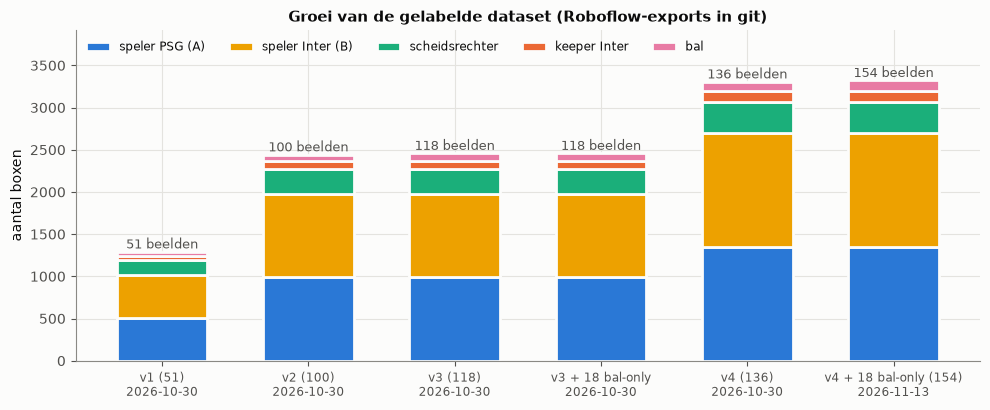

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(versions))
bottom = np.zeros(len(versions))
for c in ["player_A", "player_B", "referee", "player_B_goal_keeper", "ball"]:
    ax.bar(x, versions[c], bottom=bottom, color=CLASS_COLOR[c], edgecolor="#fcfcfb", linewidth=2,
           width=0.62, label=CLASS_NL[c])
    bottom += versions[c].values
for xi, (b, n) in enumerate(zip(bottom, versions["beelden"])):
    ax.text(xi, b + 40, f"{n} beelden", ha="center", fontsize=9, color="#52514e")
ax.set_xticks(x, [f"{v}\n{d[:10]}" for v, d in zip(versions["versie"], versions["datum"])], fontsize=8.5)
ax.set_ylabel("aantal boxen")
ax.set_title("Groei van de gelabelde dataset (Roboflow-exports in git)")
ax.legend(ncol=5, loc="upper left", fontsize=8.5)
ax.set_ylim(0, bottom.max() * 1.18)
plt.tight_layout(); plt.show()

**Wat zien we?** De dataset groeide op 30 oktober van 51 naar 136 beelden. Tussen v2 en v4 zijn vooral beelden met de bal
toegevoegd, eerst met alleen de bal gelabeld en daarna (v4) ook met alle spelers erbij. Een beeld waarin alleen de bal gelabeld is,
leert het model namelijk dat de spelers erop "achtergrond" zijn. Twee versies tellen meer beelden dan unieke frames
(118 tegen 103 en 154 tegen 136). Dat komt door 18 extra beelden met alleen een bal-label, die apart werden toegevoegd (commit
`c02c1d1`) en frames bevatten die al in de dataset zaten. **Versie v4 (136 beelden) is de dataset van het finale model**
(bewijs in sectie 4.1). In de rest van dit hoofdstuk bedoelen we met "de dataset" deze v4.

### 2.2 Het labelprotocol

Voor het labelen spraken we vooraf regels af (`docs/labeling_protocol.md`, kopie in `data/results/training/labeling_protocol.md`).
Zo labelt iedereen in het team op dezelfde manier. De belangrijkste regels:

* **Strakke box** rond de fysieke rand van de bal. Een schaduw op het gras hoort er nooit bij, anders leert het model donkere vlekken als bal zien.
* **Bewegingsonscherpte:** bij een harde pass is de bal een uitgerekte veeg. De box omvat de hele zichtbare veeg.
* **Bedekking (occlusie):** een bal die voor 30 % of meer zichtbaar is, wordt gelabeld (box rond het zichtbare deel). Minder dan 30 % zichtbaar:
  niet labelen, want een label op onzichtbare pixels leert het model op achtergrond te reageren.
* **Rand van het beeld:** alleen labelen als meer dan de helft zichtbaar is.
* **Split per tijdsblok, niet willekeurig:** opeenvolgende beelden lijken bijna identiek. Komt beeld 101 in train en beeld 102 in validatie,
  dan meet de validatie vooral geheugen. Dit noemen we data leakage.
* **Kruiscontrole:** elk teamlid controleert een batch labels van een ander.

Het protocol noemde de spelersklassen oorspronkelijk optioneel ("COCO-person volstaat"). In de praktijk hebben we ze toch allemaal gelabeld,
omdat COCO geen teams kent. Het protocol mikte op 40 tot 80 beelden. Het werden er 136, omdat de bal te weinig voorkwam.

### 2.3 Klasseverdeling

We lezen alle boxen van v4 in een tabel met de boxafmetingen in pixels van het originele beeld.

In [5]:
v4 = dv["v4 (136)"]["labels"]
box_rows = []
for name, text in v4.items():
    for cls, xc, yc, w, h in parse_labels(text):
        box_rows.append({"file": name, "frame": frame_idx(name), "klasse": CLASSES[cls],
                         "xc": xc * W, "yc": yc * H, "w_px": w * W, "h_px": h * H})
boxes = pd.DataFrame(box_rows)
boxes["size_px"] = np.sqrt(boxes.w_px * boxes.h_px)          # geometric mean of width and height

per_class = boxes.groupby("klasse").agg(boxen=("frame", "size"), beelden_met_klasse=("file", "nunique")).reindex(CLASSES)
per_class["% van de beelden"] = (100 * per_class.beelden_met_klasse / len(v4)).round(1)
per_class["gem. per beeld"] = (per_class.boxen / len(v4)).round(2)
print(f"{len(v4)} beelden, {len(boxes)} boxen, gemiddeld {len(boxes)/len(v4):.1f} boxen per beeld")
per_class

136 beelden, 3305 boxen, gemiddeld 24.3 boxen per beeld


,boxen,beelden_met_klasse,% van de beelden,gem. per beeld
klasse,,,,
ball,105,104,76.5,0.77
player_A,1351,136,100.0,9.93
player_B,1348,136,100.0,9.91
player_B_goal_keeper,134,134,98.5,0.99
referee,367,134,98.5,2.70


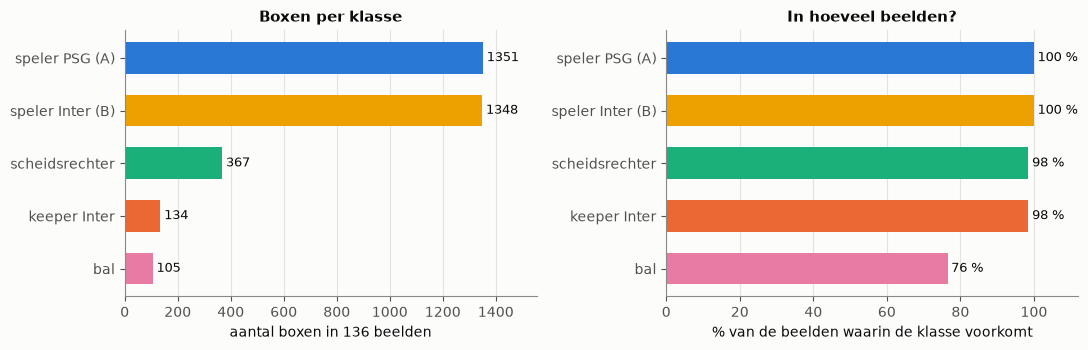

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = per_class.sort_values("boxen").index
ax = axes[0]
ax.barh([CLASS_NL[c] for c in order], per_class.loc[order, "boxen"], color=[CLASS_COLOR[c] for c in order], height=0.6)
for i, c in enumerate(order):
    ax.text(per_class.loc[c, "boxen"] + 15, i, str(per_class.loc[c, "boxen"]), va="center", fontsize=9)
ax.set_xlabel("aantal boxen in 136 beelden"); ax.set_title("Boxen per klasse"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, per_class.boxen.max() * 1.15)
ax = axes[1]
ax.barh([CLASS_NL[c] for c in order], per_class.loc[order, "% van de beelden"], color=[CLASS_COLOR[c] for c in order], height=0.6)
for i, c in enumerate(order):
    ax.text(per_class.loc[c, "% van de beelden"] + 1, i, f"{per_class.loc[c, '% van de beelden']:.0f} %", va="center", fontsize=9)
ax.set_xlabel("% van de beelden waarin de klasse voorkomt"); ax.set_title("In hoeveel beelden?"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 112)
plt.tight_layout(); plt.show()

**Wat zien we?** De dataset is sterk onevenwichtig. Per beeld staan er gemiddeld zo'n tien spelers van elk team, maar hoogstens
één bal. Tegenover één bal-box staan er meer dan 25 spelers-boxen. De bal staat in ongeveer drie kwart van de beelden en is met 105 boxen de kleinste klasse. De keeper van Inter staat in bijna elk
beeld, maar telkens maar één keer (134 boxen). De scheidsrechter en de grensrechters komen samen op ongeveer 2,7 per beeld.
Deze onevenwichtigheid is een van de redenen dat de bal het moeilijkst te leren is. De bal-fine-tune in sectie 3.5
probeert dat te compenseren met een klassengewicht (`cls_pw`).

### 2.4 Boxgroottes: hoe klein is de bal?

YOLO verkleint elk beeld eerst tot `imgsz` pixels aan de lange zijde (bij 640 dus met een factor 3). Het fijnste raster waarop
YOLO26 voorspelt heeft een stap (stride) van 8 px: één cel van dat raster beslaat 8 x 8 px van het verkleinde beeld. Een
object dat kleiner is dan één cel, is voor het netwerk nauwelijks te zien.

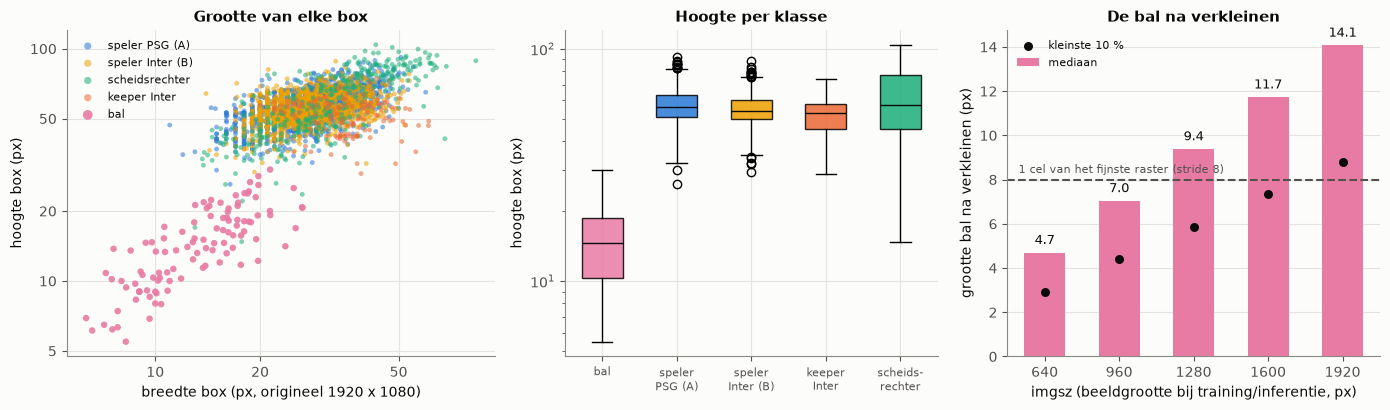

,mediane breedte (px),mediane hoogte (px),mediane sqrt(b x h) (px)
klasse,,,
ball,13.8,14.5,14.1
player_A,27.7,56.0,39.3
player_B,26.9,54.0,38.0
player_B_goal_keeper,35.0,53.0,41.8
referee,31.8,57.5,42.3


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax = axes[0]
for c in ["player_A", "player_B", "referee", "player_B_goal_keeper", "ball"]:
    b = boxes[boxes.klasse == c]
    ax.scatter(b.w_px, b.h_px, s=12 if c != "ball" else 22, alpha=0.55 if c != "ball" else 0.9,
               color=CLASS_COLOR[c], label=CLASS_NL[c], edgecolors="none")
ax.set_xscale("log"); ax.set_yscale("log")
from matplotlib.ticker import FixedLocator, ScalarFormatter, NullLocator
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(FixedLocator([5, 10, 20, 50, 100])); axis.set_major_formatter(ScalarFormatter()); axis.set_minor_locator(NullLocator())
ax.set_xlabel("breedte box (px, origineel 1920 x 1080)"); ax.set_ylabel("hoogte box (px)")
ax.set_title("Grootte van elke box"); ax.legend(fontsize=8, loc="upper left", markerscale=1.5)

ax = axes[1]
data = [boxes[boxes.klasse == c].h_px for c in CLASSES]
bp = ax.boxplot(data, vert=True, patch_artist=True, widths=0.55, medianprops=dict(color="#0b0b0b"))
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(CLASS_COLOR[c]); patch.set_alpha(0.85)
ax.set_xticks(range(1, 6), ["bal", "speler\nPSG (A)", "speler\nInter (B)", "keeper\nInter", "scheids-\nrechter"], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("hoogte box (px)"); ax.set_title("Hoogte per klasse")

ax = axes[2]
ball = boxes[boxes.klasse == "ball"]
sizes = [640, 960, 1280, 1600, 1920]
med = [ball.size_px.median() * s / W for s in sizes]
p10 = [ball.size_px.quantile(0.1) * s / W for s in sizes]
ax.bar([str(s) for s in sizes], med, color=CLASS_COLOR["ball"], width=0.55, label="mediaan")
ax.scatter([str(s) for s in sizes], p10, color="#0b0b0b", zorder=3, s=30, label="kleinste 10 %")
ax.axhline(8, color="#52514e", ls="--", lw=1.5)
ax.text(-0.35, 8.3, "1 cel van het fijnste raster (stride 8)", fontsize=8, color="#52514e")
for i, m in enumerate(med):
    ax.text(i, m + 0.4, f"{m:.1f}", ha="center", fontsize=9)
ax.set_xlabel("imgsz (beeldgrootte bij training/inferentie, px)"); ax.set_ylabel("grootte bal na verkleinen (px)")
ax.set_title("De bal na verkleinen"); ax.legend(fontsize=8, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

summary = boxes.groupby("klasse")[["w_px", "h_px", "size_px"]].median().reindex(CLASSES).round(1)
summary.columns = ["mediane breedte (px)", "mediane hoogte (px)", "mediane sqrt(b x h) (px)"]
summary

**Wat zien we?** Spelers zijn in het originele beeld ongeveer 27 x 55 px, de bal maar zo'n 14 px. Na verkleinen naar 640 px
(de standaard van YOLO en van onze eerste runs) is de bal nog geen 5 px. Dat is kleiner dan één rastercel. Die run vond de bal
dan ook nooit (sectie 3). Bij 960 px (het finale model) is de bal ongeveer 7 px, en pas vanaf 1280 px groter dan één cel.
Daarom trainden Brent en Kobe op 1600 en 1920 px, en daarom draait de app inferentie op 1280 px (notebook 02).
Een hogere resolutie vraagt wel veel meer GPU-geheugen. Bij Brent paste op 1600 px maar een batch van 2 beelden.

### 2.5 Welke frames zijn gelabeld, en hoe is er gesplitst?

In de loop van het project zijn **vier verschillende splitsingen** gebruikt. Op de tijdlijn hieronder is elk streepje één beeld van de clip.
Zo zie je meteen welke beelden in welke split zitten en waar ze overlappen.

* **v4, finaal model (Cisse):** de `data.yaml` van de export zet `train: train/images` en `val: train/images`. Alle 136 beelden zijn dus tegelijk
  train- en validatiedata.
* **Brent (smoke test):** tijdsblok. Train = frames 0-494, een buffer 495-524 die nooit gebruikt wordt, val = 525-659.
* **notebook_split (Kobe):** train = 0-62 en 525-588, val = 200-245, test = 600-658 (`data/datasets/notebook_split`).
* **ball_finetune (GPU-fine-tune):** train = frames < 200 en 246-599, val = 200-245, frames vanaf 600 weggelaten (`data/datasets/ball_finetune`).
* **GT-frames:** de 22 + 6 beelden die Kobe later met de hand aanklikte voor de systeemevaluatie (`ground_truth.json`, `ground_truth_feet.json`).

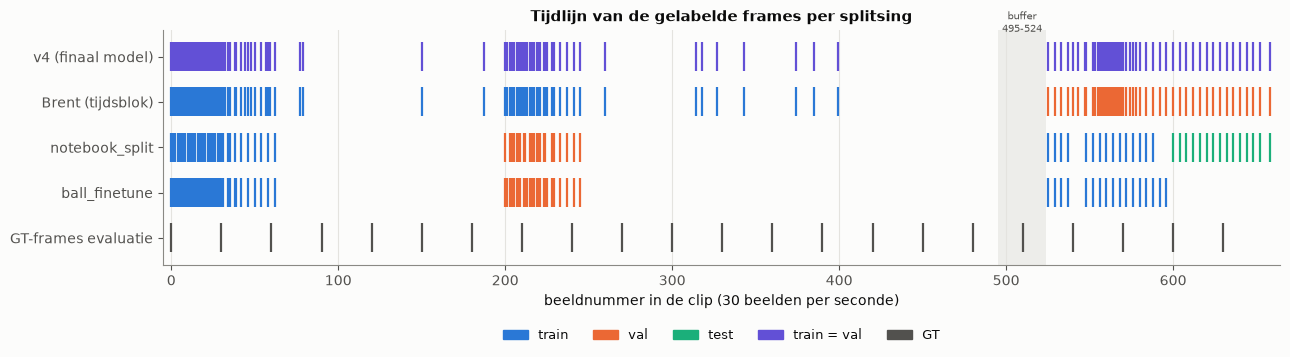

Grote gaten zonder labels (>20 frames): [(79, 150), (150, 187), (260, 314), (343, 374), (399, 525)]
GT-frames die ook in de 136 trainingsbeelden van het finale model zitten: [0, 30, 150, 210, 540, 570, 600]


In [8]:
def ds_frames(folder):
    return sorted(frame_idx(p.name) for p in (folder / "images").glob("*.jpg"))

v4_frames = sorted({frame_idx(n) for n in v4})
schemes = {
    "v4 (finaal model)": {"train = val": v4_frames},
    "Brent (tijdsblok)": {"train": [f for f in v4_frames if f <= 494], "val": [f for f in v4_frames if f >= 525]},
    "notebook_split": {s: ds_frames(DS / "notebook_split" / s) for s in ["train", "val", "test"]},
    "ball_finetune": {s: ds_frames(DS / "ball_finetune" / s) for s in ["train", "val"]},
}
gt_body = sorted(int(k) for k in json.load(open(FU / "data" / "ground_truth.json"))["frames"])
gt_feet = sorted(int(k) for k in json.load(open(FU / "data" / "ground_truth_feet.json"))["frames"])
schemes["GT-frames evaluatie"] = {"GT": sorted(set(gt_body) | set(gt_feet))}

fig, ax = plt.subplots(figsize=(13, 3.8))
labels = list(schemes)
for row, (scheme, splits) in enumerate(schemes.items()):
    y = len(labels) - 1 - row
    for split, frames in splits.items():
        ax.vlines(frames, y - 0.32, y + 0.32, color=SPLIT_COLOR[split], lw=1.6)
ax.axvspan(495, 524, ymin=0, ymax=1, color="#e4e3df", alpha=0.6, lw=0)
ax.text(509.5, len(labels) - 0.45, "buffer\n495-524", ha="center", fontsize=7.5, color="#52514e")
ax.set_yticks(range(len(labels)), labels[::-1])
ax.set_xlim(-5, 664); ax.set_ylim(-0.6, len(labels) - 0.4)
ax.set_xlabel("beeldnummer in de clip (30 beelden per seconde)")
ax.set_title("Tijdlijn van de gelabelde frames per splitsing")
ax.grid(axis="y", visible=False)
handles = [mpatches.Patch(color=SPLIT_COLOR[s], label=s) for s in ["train", "val", "test", "train = val", "GT"]]
ax.legend(handles=handles, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
plt.tight_layout(); plt.show()

gaps = [(a, b) for a, b in zip(v4_frames, v4_frames[1:]) if b - a > 20]
print("Grote gaten zonder labels (>20 frames):", gaps)
print("GT-frames die ook in de 136 trainingsbeelden van het finale model zitten:",
      sorted(set(schemes['GT-frames evaluatie']['GT']) & set(v4_frames)))

**Wat zien we?**

* De gelabelde beelden liggen in **drie dichte blokken**: het begin (0-62), een fase rond 200-245 en het einde (525-658).
  Het middenstuk (ongeveer 63-199 en 246-524, dat is meer dan de helft van de clip) heeft maar een handvol losse beelden.
  Dat is het gevolg van hoe er gelabeld is: eerst opeenvolgende beelden, daarna gericht beelden met een zichtbare bal.
* De **notebook_split** en **ball_finetune** zijn eerlijke tijdsblokken op zich. Maar het finale model heeft al hun beelden al gezien
  tijdens zijn training, want het trainde op alle 136. Wie het finale model test op de testframes 600-658, meet dus beelden die het
  model al kent (leakage). Dat geldt ook voor 7 van de 22 GT-frames (0, 30, 150, 210, 540, 570 en 600, zie de uitvoer hierboven).
* Brents tijdsblok-split is de enige die de hele dataset gebruikt en toch eerlijk valideert. Zijn val-blok (525-659)
  is één aaneengesloten scène aan het einde van de clip, dus ook dat zegt weinig over andere spelsituaties.

### 2.6 Aantallen per split

Dezelfde splitsingen in cijfers: aantal beelden en boxen per klasse. Voor `notebook_split` en `ball_finetune` lezen we de labelbestanden in de
datasetmappen. Voor v4 en Brent passen we de regel toe op de v4-labels.

In [9]:
def count_split(label_texts):
    c = {k: 0 for k in CLASSES}
    for t in label_texts:
        for cls, *_ in parse_labels(t):
            c[CLASSES[cls]] += 1
    return c

split_rows = []
split_rows.append({"splitsing": "v4 (finaal model)", "split": "train = val", "beelden": len(v4), **count_split(v4.values())})
for s, cond in [("train", lambda f: f <= 494), ("val", lambda f: f >= 525)]:
    sel = [t for n, t in v4.items() if cond(frame_idx(n))]
    split_rows.append({"splitsing": "Brent (tijdsblok)", "split": s, "beelden": len(sel), **count_split(sel)})
for ds_name, splits in [("notebook_split", ["train", "val", "test"]), ("ball_finetune", ["train", "val"])]:
    for s in splits:
        texts = [p.read_text() for p in (DS / ds_name / s / "labels").glob("*.txt")]
        split_rows.append({"splitsing": ds_name, "split": s, "beelden": len(texts), **count_split(texts)})
split_table = pd.DataFrame(split_rows).rename(columns=CLASS_NL)
split_table

,splitsing,split,beelden,bal,speler PSG (A),speler Inter (B),keeper Inter,scheidsrechter
0,v4 (finaal model),train = val,136,105,1351,1348,134,367
1,Brent (tijdsblok),train,86,76,858,858,84,313
2,Brent (tijdsblok),val,50,29,493,490,50,54
3,notebook_split,train,51,39,512,499,50,151
4,notebook_split,val,23,21,230,229,22,86
5,notebook_split,test,15,5,142,149,15,20
6,ball_finetune,train,59,43,590,580,58,173
7,ball_finetune,val,26,24,260,259,25,98


**Wat zien we?** De validatie- en testsets zijn klein. De test van notebook_split heeft 15 beelden met 5 ballen. Eén extra
gevonden bal verschuift de bal-recall daar dus met 20 procentpunten. De `ball_finetune`-data is gebouwd op de oudere export v2 (100 beelden,
`data/datasets/roboflow_train`), daarom telt ze 59 + 26 = 85 beelden en niet meer. Brents tijdsblok-split geeft 86 trainings- en
50 validatiebeelden; dat komt overeen met zijn README.

### 2.7 Voorbeeldbeelden met labels

We tekenen de v4-labels op de originele beelden uit de clip. Rechts staat telkens een uitvergroting rond de bal. Zo zie je hoe weinig
pixels het model krijgt om de bal te herkennen.

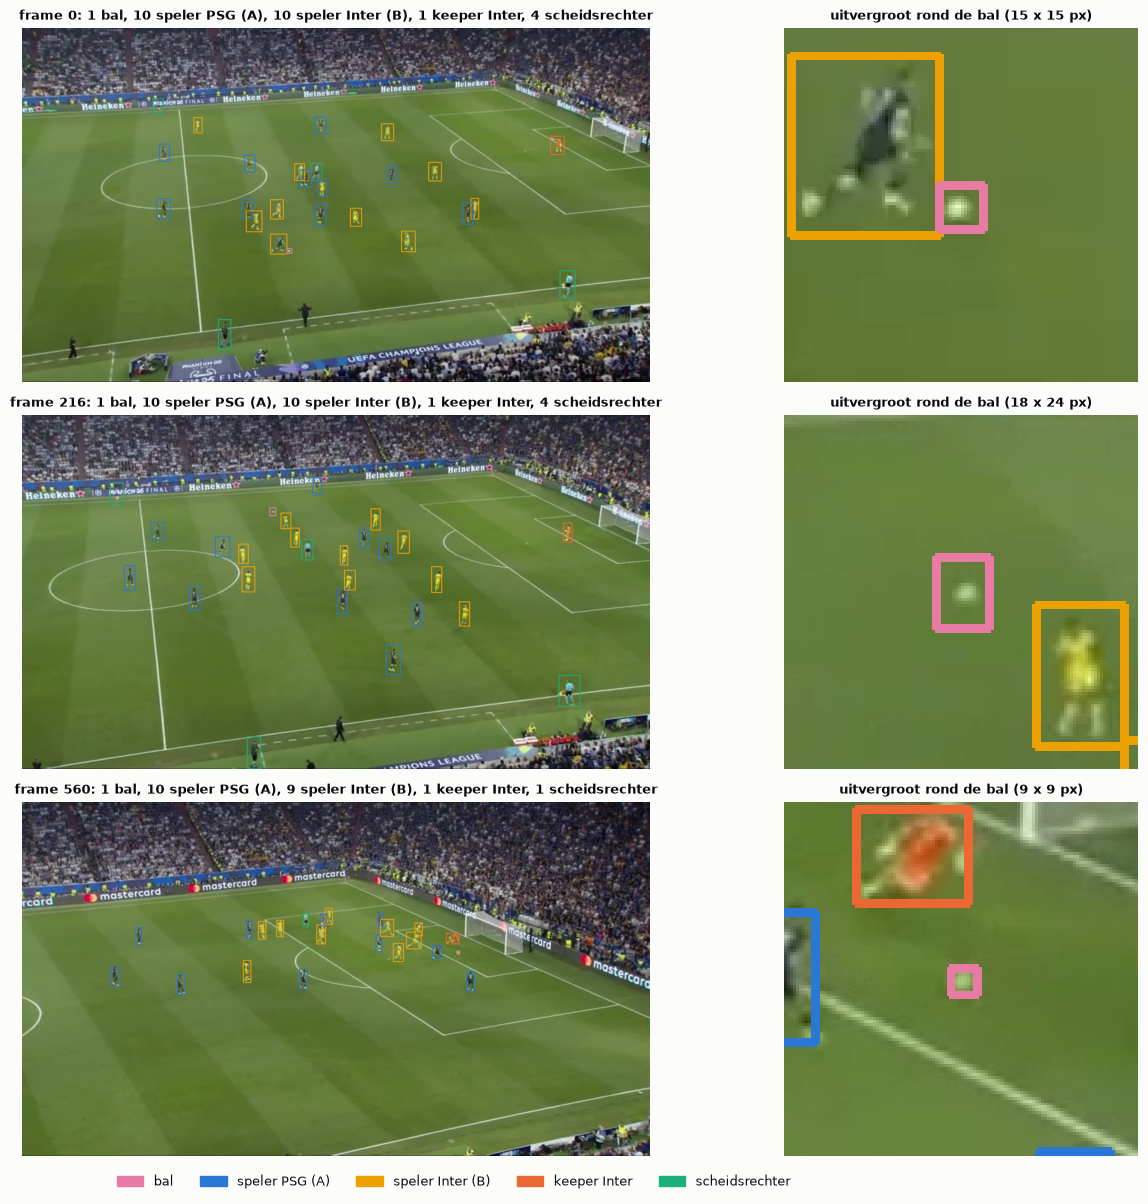

In [10]:
def read_frame(i):
    cap = cv2.VideoCapture(str(VIDEO)); cap.set(cv2.CAP_PROP_POS_FRAMES, i)
    ok, img = cap.read(); cap.release()
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def hex2rgb(h):
    return tuple(int(h[i:i + 2], 16) for i in (1, 3, 5))

def draw(img, rows, thickness=2):
    out = img.copy()
    for cls, xc, yc, w, h in rows:
        x0, y0, x1, y1 = int(xc - w / 2), int(yc - h / 2), int(xc + w / 2), int(yc + h / 2)
        cv2.rectangle(out, (x0, y0), (x1, y1), hex2rgb(CLASS_COLOR[cls]), thickness)
    return out

examples = [0, 216, 560]
fig, axes = plt.subplots(len(examples), 2, figsize=(14, 4.0 * len(examples)), gridspec_kw={"width_ratios": [3.2, 1]})
for r, f in enumerate(examples):
    b = boxes[boxes.frame == f]
    rows_ = [(k, x, y, w, h) for k, x, y, w, h in b[["klasse", "xc", "yc", "w_px", "h_px"]].itertuples(index=False)]
    img = draw(read_frame(f), rows_)
    axes[r, 0].imshow(img); axes[r, 0].axis("off")
    counts = b.klasse.value_counts()
    axes[r, 0].set_title(f"frame {f}: " + ", ".join(f"{counts.get(c, 0)} {CLASS_NL[c]}" for c in CLASSES), fontsize=9.5)
    bb = b[b.klasse == "ball"]
    if len(bb):
        cx, cy = int(bb.xc.iloc[0]), int(bb.yc.iloc[0])
        crop = img[max(cy - 60, 0):cy + 60, max(cx - 60, 0):cx + 60]
        axes[r, 1].imshow(crop, interpolation="nearest")
        axes[r, 1].set_title(f"uitvergroot rond de bal ({bb.w_px.iloc[0]:.0f} x {bb.h_px.iloc[0]:.0f} px)", fontsize=9.5)
    axes[r, 1].axis("off")
handles = [mpatches.Patch(color=CLASS_COLOR[c], label=CLASS_NL[c]) for c in CLASSES]
fig.legend(handles=handles, ncol=5, loc="lower center", fontsize=9.5, bbox_to_anchor=(0.5, -0.005))
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

**Wat zien we?** De spelers zijn duidelijke, rechtopstaande figuren met een herkenbare shirtkleur. De bal is een vlekje van een paar
pixels dat sterk lijkt op witte lijnen, de penaltystip of schoenen. Dat verklaart de typische fouten van het model (bal gemist naast
een speler, valse bal op de stip). In notebook 02 gaan we daar verder op in.

### 2.8 Hoe sterk lijken opeenvolgende beelden op elkaar?

Waarom splitsen we per tijdsblok? Omdat opeenvolgende beelden bijna gelijk zijn. We meten dat: voor elk beeld het gemiddelde absolute
verschil in grijswaarde met het vorige beeld (0 = identiek, 255 = maximaal verschillend), op een verkleinde versie (480 x 270).
De README van Brents smoke test meldde "128 exact dubbele beelden". Dat controleren we met een hash van de pixels van elk beeld.
Alle 660 beelden lezen duurt een paar seconden.

660 beelden gelezen, 660 unieke beelden (exacte kopieën: 0)
verschil met het vorige beeld: mediaan 2.83, 90e percentiel 5.55, maximum 8.01 (frame 307)
bijna-kopieën (verschil < 0,5 grijswaarde met het vorige beeld): 129; meest voorkomende afstand tussen twee bijna-kopieën: 6 beelden (101 keer)


  ter vergelijking, frames 1 uit elkaar (100/101 en 300/301): 1.57 en 7.25


  ter vergelijking, frames 5 uit elkaar (100/105 en 300/305): 6.41 en 11.83


  ter vergelijking, frames 30 uit elkaar (100/130 en 300/330): 15.63 en 16.86


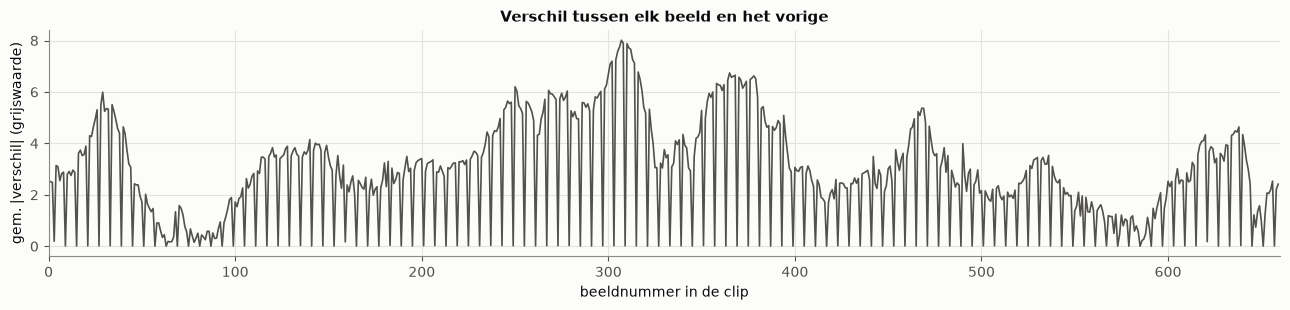

In [11]:
cap = cv2.VideoCapture(str(VIDEO))
hashes, diffs, prev = [], [], None
while True:
    ok, img = cap.read()
    if not ok:
        break
    hashes.append(hashlib.md5(img.tobytes()).hexdigest())
    small = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (480, 270)).astype(np.float32)
    diffs.append(np.nan if prev is None else float(np.abs(small - prev).mean()))
    prev = small
cap.release()
diffs = np.array(diffs)
print(f"{len(hashes)} beelden gelezen, {len(set(hashes))} unieke beelden (exacte kopieën: {len(hashes) - len(set(hashes))})")
print(f"verschil met het vorige beeld: mediaan {np.nanmedian(diffs):.2f}, 90e percentiel {np.nanpercentile(diffs, 90):.2f}, "
      f"maximum {np.nanmax(diffs):.2f} (frame {int(np.nanargmax(diffs))})")
near = np.where(diffs < 0.5)[0]
spacing = pd.Series(np.diff(near)).value_counts()
print(f"bijna-kopieën (verschil < 0,5 grijswaarde met het vorige beeld): {len(near)}; "
      f"meest voorkomende afstand tussen twee bijna-kopieën: {spacing.index[0]} beelden ({spacing.iloc[0]} keer)")
for gap in [1, 5, 30]:
    d = [np.abs(cv2.resize(read_frame(i)[:, :, 0], (480, 270)).astype(np.float32) -
                cv2.resize(read_frame(i + gap)[:, :, 0], (480, 270)).astype(np.float32)).mean() for i in (100, 300)]
    print(f"  ter vergelijking, frames {gap} uit elkaar (100/{100+gap} en 300/{300+gap}): {d[0]:.2f} en {d[1]:.2f}")

fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(np.arange(len(diffs)), diffs, color="#52514e", lw=1.2)
ax.set_xlabel("beeldnummer in de clip"); ax.set_ylabel("gem. |verschil| (grijswaarde)")
ax.set_title("Verschil tussen elk beeld en het vorige"); ax.set_xlim(0, 660)
plt.tight_layout(); plt.show()

**Wat zien we?** Bit voor bit is geen enkel beeld een kopie van een ander (de videocompressie verandert telkens een paar pixels). Maar de
grafiek toont een duidelijk zaagtandpatroon: ongeveer elk 6e beeld verschilt bijna niet van het vorige. Dat zijn **bijna-kopieën**, ongeveer
evenveel als de 128 "dubbele beelden" uit Brents README. Zo'n vast ritme ontstaat typisch als een video van 25 naar 30 beelden per seconde wordt
omgezet door telkens één beeld te herhalen; dat is een vermoeden, de bron van de clip kennen we niet. Daarnaast liggen ook gewone buurbeelden
dicht bij elkaar: het typische verschil met het vorige beeld is maar een paar grijswaarden, en pas bij beelden die verder uit elkaar liggen
groeit het verschil. Twee buurframes in train en validatie zijn voor het model dus bijna hetzelfde beeld. Daarom splitsen we per
tijdsblok, en daarom tellen 136 beelden uit drie dichte blokken als minder informatie dan 136 losse beelden uit een hele wedstrijd.

## 3. De trainingsgeschiedenis

### 3.1 Welke runs hebben we teruggevonden?

Niet elke run heeft al zijn bestanden achtergelaten. We vonden ze op drie manieren terug:

1. **In het modelbestand zelf.** Ultralytics bewaart in elk `.pt` de trainingsinstellingen (`train_args`), alle resultaten per epoch
   (`train_results`), de datum en de git-commit van de repo tijdens het trainen. Zo vonden we Brents twee runs terug.
2. **In de git-geschiedenis.** Cisse overschreef telkens dezelfde map `cisse/model/player_training`. Elke commit daarvan bevat een andere
   run, dus we halen elke versie terug met `git show <commit>:...`.
3. **In mappen met `results.csv` en `args.yaml`:** Kobe's run op 1920 px en de GPU-fine-tune.

`runs_overview.csv` vat per run samen wie, wanneer, welke data en waar de gegevens vandaan komen. Hieronder voegen we daar de
instellingen uit `args.yaml` en de resultaten uit `results.csv` aan toe. De kolom "zekerheid" zegt hoe zeker het aantal beelden is. Waar
alleen de toestand van de repo bij de commit bekend is, staat "waarschijnlijk".

In [12]:
overview = pd.read_csv(RES / "runs_overview.csv")

def load_results(run):
    df = pd.read_csv(RES / "runs" / run / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df

def load_args(run):
    return yaml.safe_load(open(RES / "runs" / run / "args.yaml", encoding="utf-8"))

results = {r: load_results(r) for r in RUNS}
args = {r: load_args(r) for r in RUNS}

def summarize(run):
    df, a = results[run], args[run]
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]          # ultralytics fitness = mAP50-95
    return {"run_id": run, "basismodel": Path(str(a["model"])).name, "imgsz": a["imgsz"], "batch": a["batch"],
            "epochs (max)": a["epochs"], "epochs gedaan": len(df), "beste epoch": int(best["epoch"]),
            "P": best["metrics/precision(B)"], "R": best["metrics/recall(B)"],
            "mAP50": best["metrics/mAP50(B)"], "mAP50-95": best["metrics/mAP50-95(B)"],
            "trainingstijd (min)": round(df["time"].iloc[-1] / 60, 1)}

table = overview.merge(pd.DataFrame([summarize(r) for r in RUNS]), on="run_id", how="left")
smoke = pd.read_csv(RES / "smoke_experiments.csv").iloc[0]
i = table.index[table.run_id == "kobe_smoke_yolo26s_640"][0]
table.loc[i, ["basismodel", "imgsz", "batch", "epochs (max)", "epochs gedaan", "P", "R", "mAP50", "mAP50-95"]] = \
    [smoke["model"], smoke["imgsz"], 4, smoke["epochs"], smoke["epochs"], smoke["precision"], smoke["recall"],
     smoke["mAP50"], smoke["mAP50-95"]]
cols = ["run_id", "persoon", "datum", "basismodel", "startgewichten", "imgsz", "batch", "epochs (max)", "epochs gedaan",
        "beste epoch", "beelden_train", "beelden_val", "validatie", "P", "R", "mAP50", "mAP50-95", "trainingstijd (min)",
        "apparaat", "zekerheid_beelden"]
table[cols].style.format({"P": "{:.3f}", "R": "{:.3f}", "mAP50": "{:.3f}", "mAP50-95": "{:.3f}"}, na_rep="–") \
    .apply(lambda r: ["font-weight: bold" if r.run_id.startswith("cisse_4") else "" for _ in r], axis=1)

,run_id,persoon,datum,basismodel,startgewichten,imgsz,batch,epochs (max),epochs gedaan,beste epoch,beelden_train,beelden_val,validatie,P,R,mAP50,mAP50-95,trainingstijd (min),apparaat,zekerheid_beelden
0,kobe_smoke_yolo26s_640,Kobe,2026-10-19,yolo26s.pt,yolo26s (COCO),640.000000,4.000000,10.000000,10.000000,–,47,4,tijdsblok (frames <=494 / >=525),0.703,0.290,0.466,0.176,–,CPU (Intel Core Ultra 7),zeker (README)
1,cisse_1_yolo26l_1280,Cisse,2026-10-30,yolo26l.pt,yolo26l (COCO),1280.000000,8.000000,100.000000,1.000000,1.000000,onbekend,onbekend,onbekend,0.682,0.292,0.343,0.131,15.000000,onbekend,onbekend
2,brent_1_yolo26m_1600,Brent,2026-10-30,yolo26m.pt,yolo26m (COCO),1600.000000,2.000000,100.000000,56.000000,36.000000,47,4,tijdsblok (frames <=494 / >=525),0.661,0.674,0.712,0.329,93.700000,NVIDIA RTX 4070 Laptop (device 0),waarschijnlijk (train.txt/val.txt in git op die dag)
3,cisse_2_yolo26n_640,Cisse,2026-10-30,yolo26n.pt,yolo26n (COCO),640.000000,16.000000,100.000000,100.000000,90.000000,118,118,validatie = trainingsbeelden,0.836,0.757,0.770,0.427,9.300000,onbekend,waarschijnlijk (stand data/ bij commit 9129fa3)
4,kobe_yolo26l_1920,Kobe,2026-10-31,yolo26l.pt,yolo26l (COCO),1920.000000,2.000000,100.000000,45.000000,30.000000,51,23,tijdsblok (notebook_split),0.855,0.629,0.672,0.277,245.000000,Intel Arc GPU (xpu),zeker (kobe/notebooks/dataset)
5,brent_2_yolo26m_1600,Brent,2026-11-09,last.pt,last.pt van brent_1,1600.000000,2.000000,100.000000,65.000000,45.000000,86,50,tijdsblok (frames <=494 / >=525),0.757,0.743,0.784,0.351,101.800000,NVIDIA RTX 4070 Laptop (device 0),waarschijnlijk (split en instellingen uit commit 2572946)
6,cisse_3_yolo26n_640,Cisse,2026-11-13,yolo26n.pt,yolo26n (COCO),640.000000,16.000000,100.000000,100.000000,90.000000,136,136,validatie = trainingsbeelden,0.844,0.774,0.781,0.430,10.800000,onbekend,waarschijnlijk (stand data/ bij commit 6172c92)
7,cisse_4_final_yolo26l_960,Cisse,2026-11-13,yolo26l.pt,yolo26l (COCO),960.000000,2.000000,100.000000,100.000000,92.000000,136,136,validatie = trainingsbeelden,0.889,0.897,0.895,0.546,55.200000,onbekend (GPU waarschijnlijk),zeker (labels.cache in commit ec70a4b)
8,gpu_ball_finetune_1280,Brent (script van Kobe),2026-11-13,best.pt,psg_vs_inter_CV.pt,1280.000000,4.000000,60.000000,16.000000,1.000000,59,26,tijdsblok (val = frames 200-245),0.948,0.913,0.941,0.468,23.400000,NVIDIA RTX 4070 Laptop,zeker (datasets/ball_finetune)


**Hoe lees je deze tabel?** De metrics zijn die van de **beste epoch** volgens ultralytics: de epoch met de hoogste mAP50-95 op de
validatieset. Die epoch wordt als `best.pt` bewaard. **Vergelijk de getallen niet blind**, want de validatiesets verschillen sterk:

* Bij Cisse 2, 3 en 4 is de validatieset gelijk aan de trainingsset. Hun mAP meet hoe goed het model zijn eigen trainingsbeelden
  terugvindt. Dat is een bovengrens en geen generalisatie.
* Bij Kobe's smoke test en Brent 1 bestaat de validatie uit **4 beelden**. Eén box meer of minder verandert dan alles.
* Brent 2 (50 val-beelden, frames 525-659) en Kobe 1920 (23 val-beelden, frames 200-245) zijn de eerlijkste metingen: mAP50 0,78 en 0,67
  bij de beste epoch (de hoogste mAP50 die ze ooit haalden was 0,80 en 0,69).
* De bal-fine-tune valideert op frames 200-245, die het startmodel (het finale model) al kende. Zijn 0,94 is dus ook te optimistisch.

Run "Cisse 1" (yolo26l op 1280) is na één epoch gestopt; welke data hij gebruikte, is niet terug te vinden. Waarschijnlijk was het geheugen
of de tijd te krap. Daarna stapte Cisse over naar het kleine yolo26n op 640, en voor het finale model naar yolo26l op 960 met batch 2.

### 3.2 Welke hyperparameters verschilden?

We zetten de belangrijkste trainingsinstellingen uit de `args.yaml`-bestanden naast elkaar. Bij runs waarvan alleen de `args.yaml` uit de map
bestaat, staat `optimizer: auto` met `lr0: 0.01`. Ultralytics vervangt dat bij korte trainingen (minder dan 10 000 iteraties) door AdamW met
`lr0 = 0,002 x 5 / (4 + aantal klassen) = 0,001111`. In de checkpoints staat die opgeloste waarde, en alle runs hier zijn zo kort.

In [13]:
keys = ["model", "imgsz", "batch", "epochs", "patience", "optimizer", "lr0", "cos_lr", "warmup_epochs", "mosaic",
        "close_mosaic", "mixup", "copy_paste", "scale", "translate", "fliplr", "hsv_h", "hsv_s", "hsv_v", "erasing", "cls_pw", "cache"]
hp = pd.DataFrame({RUN_LABEL[r]: {k: (Path(str(args[r].get(k))).name if k == "model" else args[r].get(k)) for k in keys} for r in RUNS})
def highlight_diff(row):
    vals = row.astype(str)
    common = vals.mode().iloc[0]
    return ["background-color: #fdf0d5" if v != common else "" for v in vals]
hp.style.apply(highlight_diff, axis=1)

,Cisse 1 · 26l · 1280,Brent 1 · 26m · 1600,Cisse 2 · 26n · 640,Kobe · 26l · 1920,Brent 2 · 26m · 1600,Cisse 3 · 26n · 640,Cisse 4 · 26l · 960 (FINAAL),Bal-fine-tune · 26l · 1280
model,yolo26l.pt,yolo26m.pt,yolo26n.pt,yolo26l.pt,last.pt,yolo26n.pt,yolo26l.pt,best.pt
imgsz,1280,1600,640,1920,1600,640,960,1280
batch,8,2,16,2,2,16,2,4
epochs,100,100,100,100,100,100,100,60
patience,100,20,100,15,20,100,25,15
optimizer,auto,AdamW,auto,auto,AdamW,auto,auto,auto
lr0,0.010000,0.001111,0.010000,0.010000,0.001111,0.010000,0.010000,0.010000
cos_lr,False,False,False,True,False,False,True,True
warmup_epochs,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
mosaic,1.000000,0.200000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000


**Wat zien we?** (Een geel vakje wijkt af van de meest voorkomende waarde in die rij.)

* **Mosaic** (vier beelden in één trainingsbeeld plakken) stond bij de meeste runs uit of laag (0 tot 0,2). Mosaic maakt objecten kleiner,
  en dat is voor onze al kleine bal nadelig. Kobe's run en de bal-fine-tune lieten de standaard 1,0 staan.
* Cisse's finale run voegde **mixup 0,15** (twee beelden doorzichtig over elkaar) en **copy-paste 0,1** toe, en zette `scale` op 0,2
  (minder in- en uitzoomen), zodat spelers en bal hun echte grootte ongeveer houden.
* Brent 2 vertrok niet van COCO maar van de laatste gewichten van Brent 1 (`last.pt`): een tweede trainingsronde op meer data.
* De bal-fine-tune is de enige met `cls_pw: 0.5`, een klassengewicht dat zeldzame klassen (de bal) zwaarder laat doorwegen in de klassenverlies.

### 3.3 Trainingscurves naast elkaar

Per epoch berekent ultralytics op de validatieset precision, recall, mAP50 en mAP50-95. **mAP50** is de gemiddelde precisie over de klassen
waarbij een voorspelling telt als ze voor minstens 50 % overlapt (IoU >= 0,5) met het label. **mAP50-95** is het gemiddelde over strengere drempels
van 0,50 tot 0,95 en beloont dus ook nauwkeurige boxen. Een doorgetrokken lijn is een run met echte (tijdsblok-)validatie, een stippellijn een run
die op zijn eigen trainingsbeelden valideert.

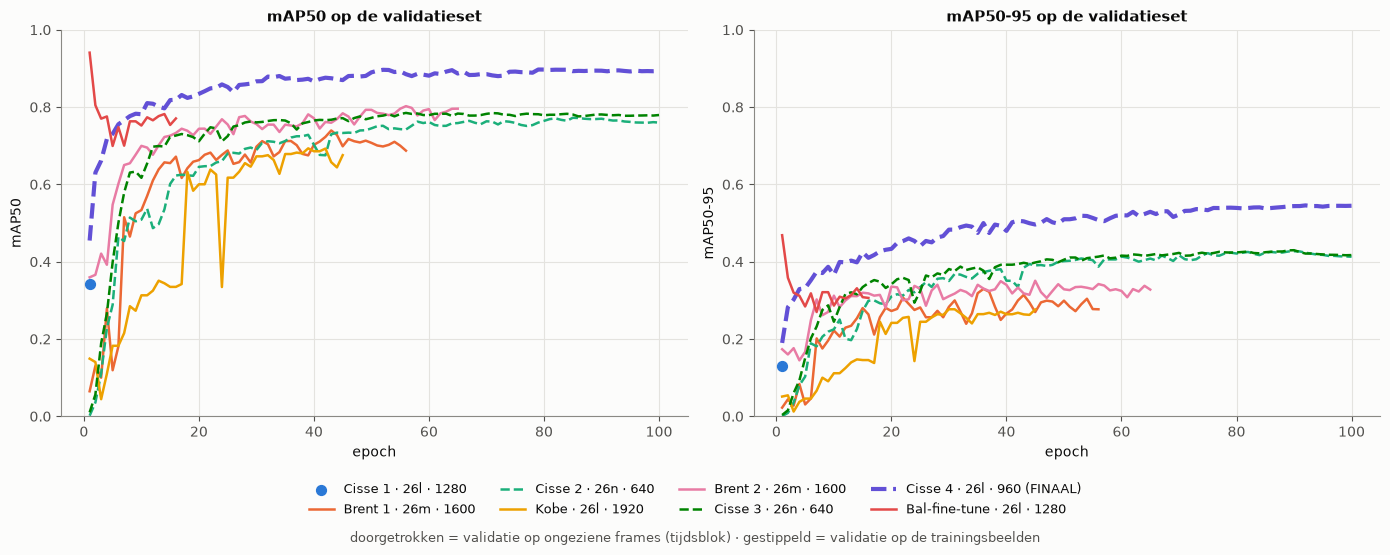

In [14]:
honest = {"brent_1_yolo26m_1600", "kobe_yolo26l_1920", "brent_2_yolo26m_1600", "gpu_ball_finetune_1280"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)
for ax, metric, title in [(axes[0], "metrics/mAP50(B)", "mAP50 op de validatieset"),
                          (axes[1], "metrics/mAP50-95(B)", "mAP50-95 op de validatieset")]:
    for r in RUNS:
        df = results[r]
        ls = "-" if r in honest else "--"
        lw = 3 if r.startswith("cisse_4") else 1.8
        if len(df) == 1:
            ax.scatter(df.epoch, df[metric], color=RUN_COLOR[r], s=50, zorder=3, label=RUN_LABEL[r])
        else:
            ax.plot(df.epoch, df[metric], ls=ls, lw=lw, color=RUN_COLOR[r], label=RUN_LABEL[r])
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel(metric.split("/")[1].replace("(B)", "")); ax.set_ylim(0, 1)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.11), fontsize=9)
fig.text(0.5, -0.14, "doorgetrokken = validatie op ongeziene frames (tijdsblok) · gestippeld = validatie op de trainingsbeelden",
         ha="center", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

**Wat zien we?**

* **Groter model en hogere resolutie werken.** Op dezelfde soort validatie (de trainingsbeelden) haalt Cisse's yolo26l op 960 een mAP50-95
  van 0,55, tegen 0,43 voor yolo26n op 640 (Cisse 2 en 3). Hij stijgt ook veel sneller.
* **Meer data helpt.** Cisse 3 (zelfde instellingen als Cisse 2, maar 136 in plaats van 118 beelden) eindigt iets hoger. Brent 2
  (86 trainingsbeelden, verder getraind vanaf Brent 1) ligt duidelijk boven Brent 1, maar Brent 1 valideerde op maar 4 beelden.
* **Early stopping.** Brent en Kobe stopten vóór epoch 100. Ultralytics stopt als de mAP50-95 een aantal epochs (`patience`) niet meer verbetert.
* **De bal-fine-tune daalt meteen.** Zijn beste epoch is de eerste, daarna zakt hij weg. Dat bespreken we in sectie 3.5.
* De runs op echte validatie (doorgetrokken) liggen allemaal duidelijk lager dan het finale model op zijn trainingsbeelden.
  Het verschil (mAP50 0,67 tot 0,78 tegen 0,895) is een ruwe aanwijzing van hoeveel het finale model op ongeziene frames zou verliezen.

### 3.4 De finale run in detail: verliezen en metrics

YOLO26 optimaliseert drie verliestermen. **box_loss** meet hoe goed de voorspelde box overlapt met het label (op basis van IoU).
**cls_loss** meet of de juiste klasse voorspeld wordt (binaire kruisentropie per klasse). **l1_loss** is de L1-afstand tussen de voorspelde en
de echte randen van de box. Die vervangt in YOLO26 de "distribution focal loss" van YOLOv8/11, daarom heet de kolom niet meer `dfl_loss`.
Train-verliezen worden tijdens de epoch op de geaugmenteerde trainingsbeelden gemeten, val-verliezen achteraf op de validatiebeelden
(hier dezelfde beelden, zonder augmentatie).

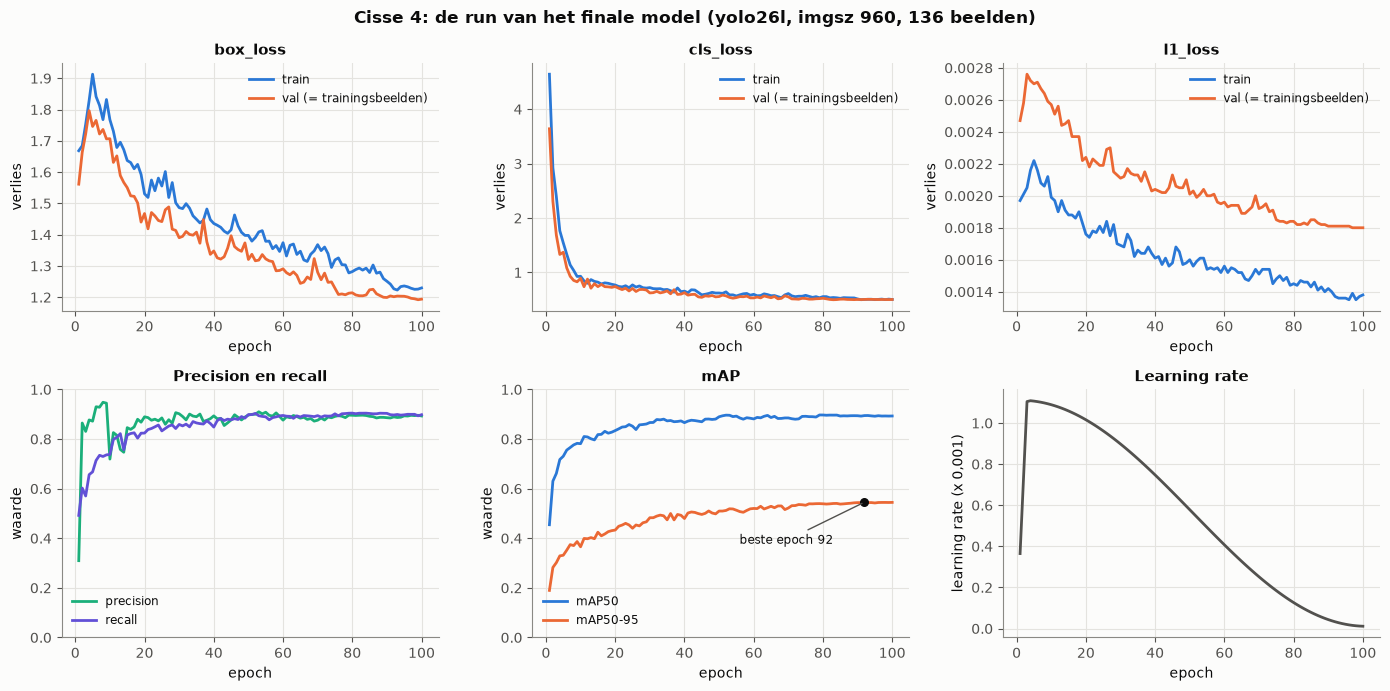

Beste epoch 92: P 0.889, R 0.897, mAP50 0.895, mAP50-95 0.546
Totale trainingstijd 55 min, gemiddeld 27 s per epoch


In [15]:
df = results["cisse_4_final_yolo26l_960"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, name in zip(axes[0], ["box_loss", "cls_loss", "l1_loss"]):
    ax.plot(df.epoch, df[f"train/{name}"], color="#2a78d6", label="train")
    ax.plot(df.epoch, df[f"val/{name}"], color="#eb6834", label="val (= trainingsbeelden)")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("verlies"); ax.legend(fontsize=8.5)
ax = axes[1, 0]
ax.plot(df.epoch, df["metrics/precision(B)"], color="#1baf7a", label="precision")
ax.plot(df.epoch, df["metrics/recall(B)"], color="#6250d6", label="recall")
ax.set_title("Precision en recall"); ax.set_xlabel("epoch"); ax.set_ylabel("waarde"); ax.set_ylim(0, 1); ax.legend(fontsize=8.5)
ax = axes[1, 1]
ax.plot(df.epoch, df["metrics/mAP50(B)"], color="#2a78d6", label="mAP50")
ax.plot(df.epoch, df["metrics/mAP50-95(B)"], color="#eb6834", label="mAP50-95")
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
ax.scatter([best.epoch], [best["metrics/mAP50-95(B)"]], color="#0b0b0b", zorder=3, s=30)
ax.annotate(f"beste epoch {int(best.epoch)}", (best.epoch, best["metrics/mAP50-95(B)"]), xytext=(-90, -30),
            textcoords="offset points", fontsize=8.5, arrowprops=dict(arrowstyle="-", color="#52514e"))
ax.set_title("mAP"); ax.set_xlabel("epoch"); ax.set_ylabel("waarde"); ax.set_ylim(0, 1); ax.legend(fontsize=8.5)
ax = axes[1, 2]
ax.plot(df.epoch, df["lr/pg0"] * 1000, color="#52514e")
ax.set_title("Learning rate"); ax.set_xlabel("epoch"); ax.set_ylabel("learning rate (x 0,001)")
plt.suptitle("Cisse 4: de run van het finale model (yolo26l, imgsz 960, 136 beelden)", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Beste epoch {int(best.epoch)}: P {best['metrics/precision(B)']:.3f}, R {best['metrics/recall(B)']:.3f}, "
      f"mAP50 {best['metrics/mAP50(B)']:.3f}, mAP50-95 {best['metrics/mAP50-95(B)']:.3f}")
print(f"Totale trainingstijd {df['time'].iloc[-1]/60:.0f} min, gemiddeld {df['time'].diff().median():.0f} s per epoch")

**Wat zien we?**

* Het klassenverlies zakt in de eerste epochs zeer snel, van 4,6 naar onder 1 binnen 10 epochs. Het model kent "persoon" en "bal" al van COCO en
  moet vooral nog de nieuwe indeling in 5 klassen leren. Daarna dalen alle verliezen rustig verder.
* Train- en val-verlies lopen gelijk op. Normaal zou je zo overfitting opsporen (val stijgt, train daalt), maar hier kan dat niet, omdat
  de validatiebeelden dezelfde zijn als de trainingsbeelden. Deze grafiek zegt dus niets over overfitting.
* De learning rate stijgt eerst 3 epochs lang (warm-up) en daalt daarna volgens een cosinus (`cos_lr: true`) tot bijna nul.
  Daardoor vlakken de curves op het einde af en is er weinig verschil tussen de laatste epochs.
* De beste epoch is 92 (mAP50-95 0,546). Vanaf ongeveer epoch 80 verbetert er nauwelijks nog iets. De instelling `close_mosaic` (de laatste
  10 epochs zonder mosaic) had hier geen effect, omdat mosaic al op 0 stond.
* Het l1-verlies op de validatiebeelden blijft hoger dan op de geaugmenteerde trainingsbeelden. Dat is een gevolg van hoe en wanneer beide
  gemeten worden, geen teken van overfitting.

### 3.5 De bal-fine-tune: een mislukte poging

Na het finale model probeerden we de bal beter te leren door `psg_vs_inter_CV.pt` nog verder te trainen op 1280 px, met klassengewicht
`cls_pw 0.5` en een eerlijke tijdsblok-split (`ball_finetune`). Kobe schreef het script. Omdat Kobe geen GPU heeft,
draaide het op een RTX 4070 Laptop; de paden in de logbestanden wijzen naar de computer van Brent. Het resultaat staat in
`models/experimenten/best_ball_ft.pt`.

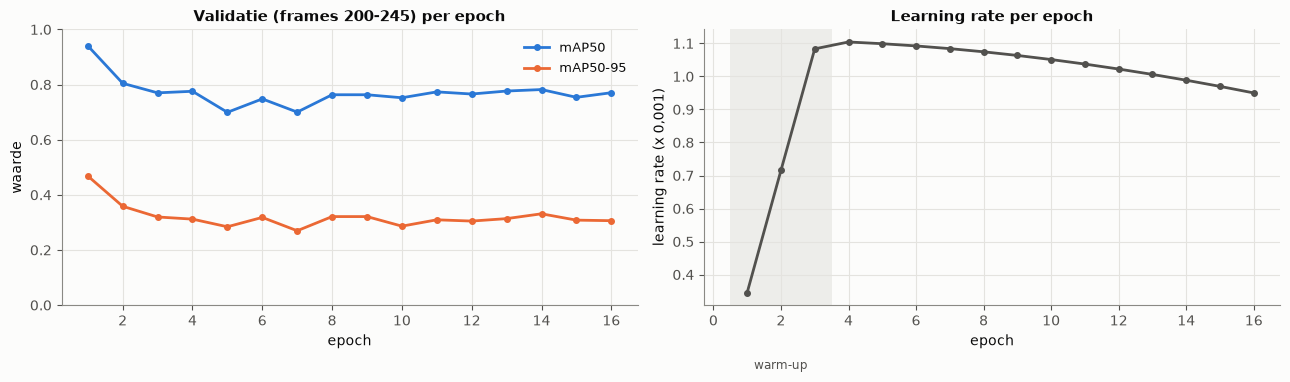

 epoch  metrics/mAP50(B)  metrics/mAP50-95(B)   lr/pg0
     1           0.94069              0.46844 0.000346
     2           0.80460              0.35847 0.000715
     3           0.76998              0.31966 0.001083
     4           0.77566              0.31186 0.001104
     5           0.69936              0.28411 0.001099


In [16]:
df = results["gpu_ball_finetune_1280"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(df.epoch, df["metrics/mAP50(B)"], color="#2a78d6", marker="o", ms=4, label="mAP50")
ax.plot(df.epoch, df["metrics/mAP50-95(B)"], color="#eb6834", marker="o", ms=4, label="mAP50-95")
ax.set_ylim(0, 1); ax.set_xlabel("epoch"); ax.set_ylabel("waarde"); ax.legend(fontsize=9)
ax.set_title("Validatie (frames 200-245) per epoch")
ax = axes[1]
ax.plot(df.epoch, df["lr/pg0"] * 1000, color="#52514e", marker="o", ms=4)
ax.axvspan(0.5, 3.5, color="#e4e3df", alpha=0.6, lw=0); ax.text(2, ax.get_ylim()[1] * 0.1, "warm-up", ha="center", fontsize=8.5, color="#52514e")
ax.set_xlabel("epoch"); ax.set_ylabel("learning rate (x 0,001)"); ax.set_title("Learning rate per epoch")
plt.tight_layout(); plt.show()
print(df[["epoch", "metrics/mAP50(B)", "metrics/mAP50-95(B)", "lr/pg0"]].head(5).to_string(index=False))

**Wat zien we?** De beste epoch is **epoch 1**, wanneer de learning rate nog bijna nul is en het model dus nog bijna gelijk is aan
het startmodel. Zodra de warm-up de learning rate opdrijft tot ongeveer 0,0011 (de standaardwaarde voor een training vanaf COCO),
zakt de mAP50 van 0,94 naar ongeveer 0,75 en herstelt hij niet meer. Na 15 epochs zonder verbetering stopte early stopping de run (16 epochs).

De verklaring: een model dat al goed getraind is, verder trainen met de learning rate van een nieuwe training "schudt" de geleerde gewichten
door elkaar. Daarbij zette de fine-tune mosaic terug op 1,0 en `scale` op 0,5, de standaardwaarden, terwijl het startmodel zonder mosaic
en met `scale 0.2` was getraind. Een betere poging zou een lr0 van ongeveer 10 keer kleiner gebruiken, zonder warm-up, met dezelfde augmentatie
als de oorspronkelijke run, en eventueel de backbone bevriezen (`freeze`). Omdat `best.pt` van deze fine-tune in feite epoch 1 is, verschilt hij
weinig van het origineel. Notebook 02 toont dat hij op de pijplijn niet beter scoorde. Het finale model bleef daarom `psg_vs_inter_CV.pt`.

### 3.6 Wat géén echte run is: `runs/detect/` in de root

In de root van de repository staat nog een map `runs/detect/`. Voor de volledigheid hebben we ze gecontroleerd, zodat niemand ze voor een
van onze trainingen aanziet:

* `runs/detect/runs/n640/`: een yolo26n-test van 1 epoch op Kobe's laptop (Intel-GPU, `device: xpu`), zonder resultaten of gewichten. Afgebroken.
* `runs/detect/train/`: een **per ongeluk gestarte** training. Zie de instellingen hieronder: dataset `coco8.yaml` (de voorbeelddataset van ultralytics met 8 beelden),
  startgewichten uit een rooktest van het GPU-script, op de processor. Ultralytics start zo'n training als je `model.train()` aanroept zonder `data`.
  Alle metrics zijn 0, dus de run heeft niets met ons model te maken.

In [17]:
acc_args = load_args("accident_runs_detect_train")
acc = load_results("accident_runs_detect_train")
print({k: acc_args[k] for k in ["data", "imgsz", "epochs", "device"]}, "| startgewichten:", Path(acc_args["model"]).parent.parent.name, "/", Path(acc_args["model"]).name)
print(f"{len(acc)} epochs, hoogste mAP50 = {acc['metrics/mAP50(B)'].max()}")

{'data': 'coco8.yaml', 'imgsz': 320, 'epochs': 100, 'device': 'cpu'} | startgewichten: train_320_b2 / last.pt
42 epochs, hoogste mAP50 = 0


## 4. Het finale model

### 4.1 Waar komt `psg_vs_inter_CV.pt` vandaan?

Het bestand heet in de app-map `models/best.pt` en is voor deze inlevering hernoemd. We bewijzen uit welke run het komt:

1. de `train_args` in het bestand vergelijken met Cisse's `args.yaml`;
2. de `train_results` in het bestand vergelijken met Cisse's `results.csv`;
3. de lijst van trainingsbeelden. Die halen we uit de labelcache van ultralytics (`labels.cache`), die tijdens deze training werd geschreven
   en mee in commit `ec70a4b` ("momenteel beste model") belandde (`final_model_train_files.txt`).

In [18]:
ta = ckpt["train_args"]
print("Datum checkpoint     :", ckpt["date"], "| ultralytics", ckpt["version"])
print("Git tijdens training :", ckpt["git"]["branch"], ckpt["git"]["commit"][:7], f"('{ckpt['git']['message']}')")
print("Run-map              :", ta["project"].split("\\")[-2:], ta["name"])

cis_args = args["cisse_4_final_yolo26l_960"]
diff = {k: (cis_args.get(k), ta.get(k)) for k in sorted(set(ta) | set(cis_args)) if str(cis_args.get(k)) != str(ta.get(k))}
print("\nVerschillen tussen cisse/.../args.yaml en de train_args in het model:")
for k, (a_, b_) in diff.items():
    print(f"  {k:16s} args.yaml = {a_!s:10s}  model = {b_}")

tr = pd.DataFrame(ckpt["train_results"])
same = np.allclose(tr["metrics/mAP50-95(B)"].values, results["cisse_4_final_yolo26l_960"]["metrics/mAP50-95(B)"].values)
print(f"\ntrain_results in het model ({len(tr)} epochs) identiek aan cisse/.../results.csv: {same}")
print("train_metrics in het model (beste epoch):", {k: v for k, v in ckpt["train_metrics"].items() if k.startswith("metrics")})

train_files = [l.strip() for l in open(RES / "final_model_train_files.txt") if l.strip() and not l.startswith("#")]
same_files = {Path(f).stem for f in train_files} == {Path(f).stem for f in v4}
print(f"\nlabels.cache van die training: {len(train_files)} beelden; zelfde bestanden als export v4: {same_files}")

Datum checkpoint     : 2026-11-13T11:04:33.774002+01:00 | ultralytics 8.4.193
Git tijdens training : CV-yolomodel 6172c92 ('vordering model')
Run-map              : ['cisse', 'model'] player_training

Verschillen tussen cisse/.../args.yaml en de train_args in het model:
  lr0              args.yaml = 0.01        model = 0.001111
  optimizer        args.yaml = auto        model = AdamW
  save_dir         args.yaml = C:\school\AI\Deep Learning\ComputerVision\CV-Challenge\cisse\model\player_training  model = None
  warmup_bias_lr   args.yaml = 0.1         model = 0.0

train_results in het model (100 epochs) identiek aan cisse/.../results.csv: True
train_metrics in het model (beste epoch): {'metrics/precision(B)': 0.88931, 'metrics/recall(B)': 0.89706, 'metrics/mAP50(B)': 0.89463, 'metrics/mAP50-95(B)': 0.54556}

labels.cache van die training: 136 beelden; zelfde bestanden als export v4: True


**Wat zien we?** De instellingen en de resultaten per epoch zijn identiek aan Cisse's laatste run (commit `ec70a4b`), en de trainingsbeelden
zijn exact de 136 beelden van export v4. De enige verschillen met `args.yaml` zijn de waarden die ultralytics zelf invult: `optimizer auto` wordt
`AdamW`, `lr0` wordt 0,001111 en `warmup_bias_lr` wordt 0 (bij Adam-achtige optimizers zet ultralytics die op 0). `save_dir` wordt bij het
opslaan van het model leeggemaakt. Het model is dus zeker
**Cisse 4: yolo26l vanaf COCO, imgsz 960, 100 epochs, batch 2, 136 beelden, validatie op de trainingsbeelden**, getraind op 13 november 2026.

### 4.2 Architectuur

YOLO26 bestaat zoals elke YOLO uit drie delen:

* **Backbone** (lagen 0-10): convolutieblokken (`Conv`, `C3k2`) die het beeld stap voor stap verkleinen (stride 2, 4, 8, 16, 32) en steeds
  abstractere kenmerken berekenen, plus `SPPF` (pooling over meerdere schalen) en `C2PSA` (een aandachtsblok).
* **Neck** (lagen 11-22): combineert kenmerken van verschillende schalen (`Upsample` + `Concat`, een FPN/PAN-structuur), zodat ook de fijne
  laag op stride 8 semantische informatie krijgt. Die laag is belangrijk voor kleine objecten zoals de bal.
* **Head** (`Detect`): voorspelt per rastercel op drie schalen (stride 8, 16 en 32) een box en een score per klasse. YOLO26 heeft geen
  "distribution focal loss" meer (`reg_max = 1`) en heeft naast de gewone kop een NMS-vrije één-op-één-kop (zie notebook 02 voor NMS).

YOLO26l summary: 392 layers, 26,184,054 parameters, 0 gradients, 93.5 GFLOPs


YOLO26l: 392 lagen, 26,184,054 parameters, 93.5 GFLOPs (bij 640 x 640)
strides van de head: [8.0, 16.0, 32.0] | reg_max: 1 | klassen: 5
deel
backbone    12,833,600 (49 %)
neck        10,544,128 (40 %)
head         2,806,326 (11 %)


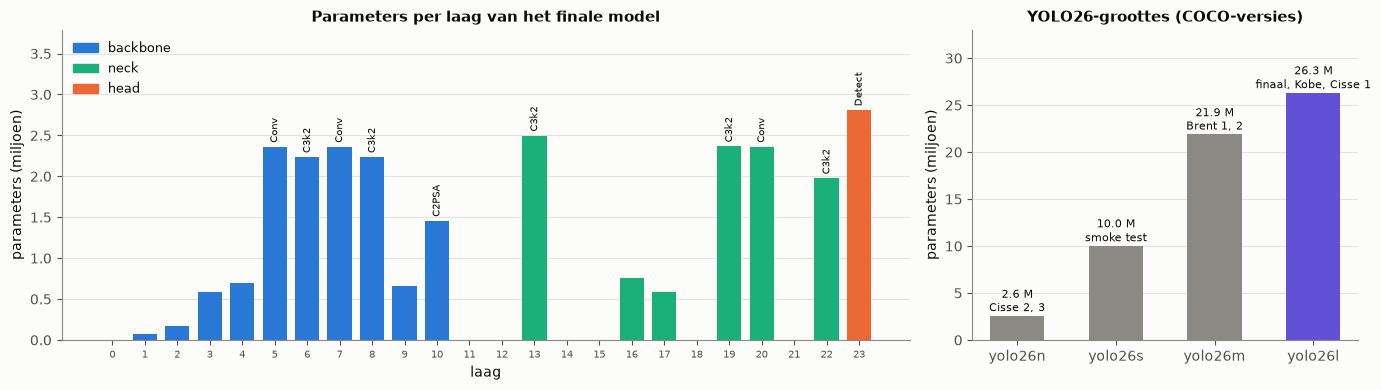

COCO yolo26l: 26,299,704 parameters; ons model: 26,184,054 -> 115,650 minder (de klassenuitgang van de head gaat van 80 naar 5 klassen; de rest wordt overgenomen)


In [19]:
from ultralytics import YOLO
yolo = YOLO(str(MODEL))
n_layers, n_params, _, gflops = yolo.info()
net = yolo.model
n_backbone = len(net.yaml["backbone"])
rows = []
for i, m in enumerate(net.model):
    rows.append({"laag": i, "type": type(m).__name__, "deel": "backbone" if i < n_backbone else ("head" if i == len(net.model) - 1 else "neck"),
                 "parameters": sum(p.numel() for p in m.parameters())})
layers = pd.DataFrame(rows)
head = net.model[-1]
print(f"YOLO26{net.yaml.get('scale', '')}: {n_layers} lagen, {n_params:,} parameters, {gflops:.1f} GFLOPs (bij 640 x 640)")
print("strides van de head:", head.stride.tolist(), "| reg_max:", head.reg_max, "| klassen:", head.nc)
print(layers.groupby("deel", sort=False).parameters.sum().apply(lambda v: f"{v:,} ({100*v/n_params:.0f} %)").to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
part_color = {"backbone": "#2a78d6", "neck": "#1baf7a", "head": "#eb6834"}
ax.bar(layers.laag, layers.parameters / 1e6, color=[part_color[d] for d in layers.deel], width=0.75)
for _, r in layers.iterrows():
    if r.parameters > 1.2e6:
        ax.text(r.laag, r.parameters / 1e6 + 0.05, r.type, ha="center", fontsize=7, rotation=90, va="bottom")
ax.set_xlabel("laag"); ax.set_ylabel("parameters (miljoen)"); ax.set_title("Parameters per laag van het finale model")
ax.legend(handles=[mpatches.Patch(color=c, label=d) for d, c in part_color.items()], fontsize=9)
ax.set_xticks(layers.laag); ax.tick_params(axis="x", labelsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylim(0, layers.parameters.max() / 1e6 * 1.35)

sizes = pd.read_csv(RES / "coco_model_sizes.csv")
ax = axes[1]
used = {"yolo26n": "Cisse 2, 3", "yolo26s": "smoke test", "yolo26m": "Brent 1, 2", "yolo26l": "finaal, Kobe, Cisse 1"}
ax.bar(sizes.model, sizes.parameters / 1e6, color=["#8a8984", "#8a8984", "#8a8984", "#6250d6"], width=0.55)
for i, r in sizes.iterrows():
    ax.text(i, r.parameters / 1e6 + 0.5, f"{r.parameters/1e6:.1f} M\n{used[r.model]}", ha="center", fontsize=8)
ax.set_ylabel("parameters (miljoen)"); ax.set_title("YOLO26-groottes (COCO-versies)"); ax.set_ylim(0, 33); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

coco_l = int(sizes.loc[sizes.model == "yolo26l", "parameters"].iloc[0])
print(f"COCO yolo26l: {coco_l:,} parameters; ons model: {n_params:,} -> {coco_l - n_params:,} minder "
      f"(de klassenuitgang van de head gaat van 80 naar 5 klassen; de rest wordt overgenomen)")

**Wat zien we?** De meeste parameters zitten in de diepe lagen van de backbone en de neck (blokken met veel kanalen op lage resolutie).
Ons model heeft op enkele tienduizenden na evenveel parameters als het COCO-yolo26l. Het enige deel dat bij transfer learning echt opnieuw
begint, is de laatste laag van de classificatietak in de head: die gaat van 80 naar 5 uitgangen. Alle andere gewichten starten vanuit COCO
en worden tijdens de training verder bijgesteld (`freeze: null`, er is niets bevroren). Het l-model is ongeveer 10 keer zo groot als het
n-model en heeft daardoor meer capaciteit voor fijne verschillen, zoals de keeper (oranje) tegenover een speler in het geel.

### 4.3 Resultaten per klasse

Ultralytics bewaarde voor de finale run geen tabel per klasse. Twee bronnen geven er toch een beeld van:

1. **De GPU-run** evalueerde het finale model op de **testsplit van notebook_split** (15 beelden, frames 600-658) op imgsz 960, met
   per-klasse P, R, AP50 en AP50-95 en de volledige PR-curves (`gpu_test_metrics_all.csv`, `gpu_test_curves_final_model.npz`).
   **Let op:** het model trainde op al deze 15 beelden. De cijfers zijn dus te optimistisch, behalve voor de bal, die ook hier zwak blijft.
2. **De figuren van Cisse's run** (confusion matrix, PR-curve) op de validatieset, die gelijk is aan de trainingsset.

Hoe goed het model is op beelden die het nooit zag, onderzoeken we in notebook 02 en met de handmatige ground truth in de systeemevaluatie.

,instances,precision,recall,mAP50,mAP50-95
class,,,,,
ball,5,0.866,0.200,0.195,0.078
player_A,142,0.986,0.981,0.994,0.783
player_B,149,0.987,0.987,0.993,0.843
player_B_goal_keeper,15,0.966,1.000,0.995,0.820
referee,20,0.908,0.985,0.942,0.685
all,331,0.943,0.831,0.824,0.642


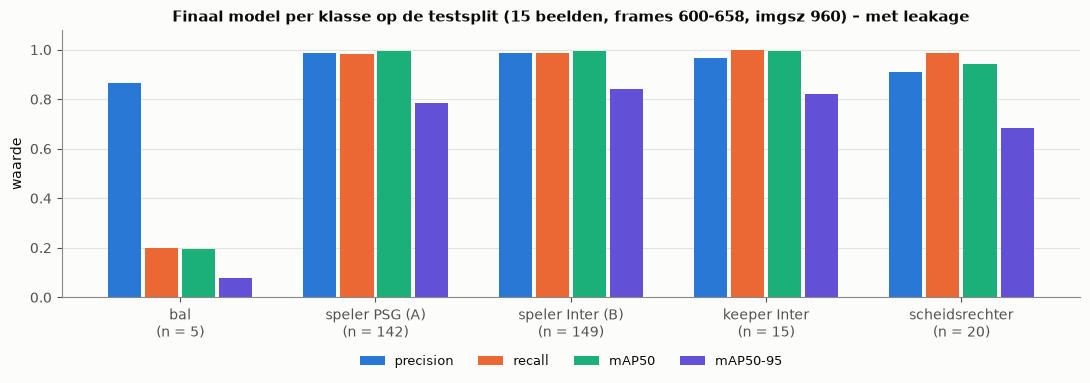

In [20]:
m = pd.read_csv(RES / "gpu_test_metrics_all.csv")
per_cls = m[(m.model == "best.pt") & (m.view == "classes") & (m.imgsz == 960)].set_index("class")
display(per_cls[["instances", "precision", "recall", "mAP50", "mAP50-95"]].round(3))

fig, ax = plt.subplots(figsize=(11, 4))
metrics = ["precision", "recall", "mAP50", "mAP50-95"]
mcolor = dict(zip(metrics, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]))
x = np.arange(len(CLASSES)); wbar = 0.19
for j, mt in enumerate(metrics):
    ax.bar(x + (j - 1.5) * wbar, per_cls.loc[CLASSES, mt], width=wbar - 0.02, color=mcolor[mt], label=mt)
ax.set_xticks(x, [f"{CLASS_NL[c]}\n(n = {int(per_cls.loc[c, 'instances'])})" for c in CLASSES])
ax.set_ylim(0, 1.08); ax.set_ylabel("waarde"); ax.grid(axis="x", visible=False)
ax.set_title("Finaal model per klasse op de testsplit (15 beelden, frames 600-658, imgsz 960) – met leakage")
ax.legend(ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17))
plt.tight_layout(); plt.show()

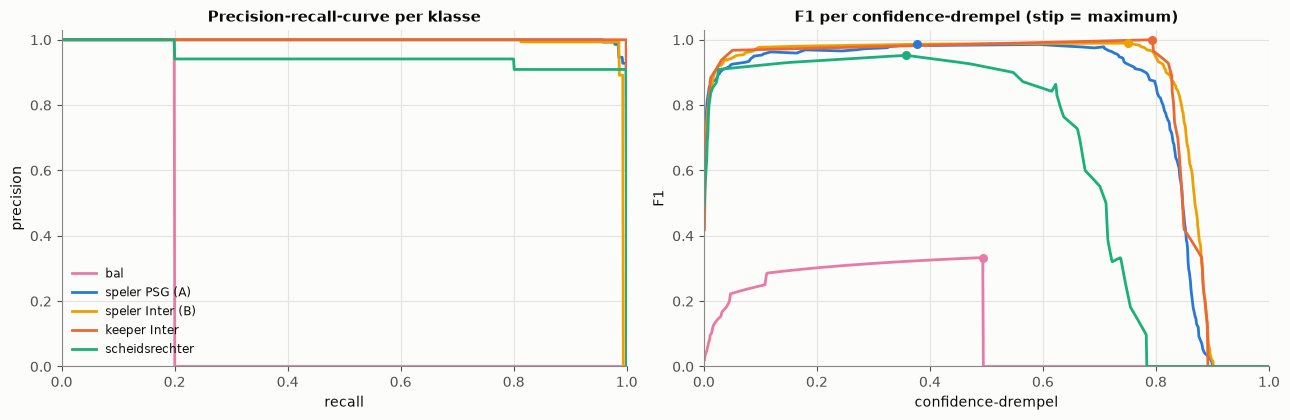

Confidence met de hoogste F1 per klasse: {'bal': 0.49, 'speler PSG (A)': 0.38, 'speler Inter (B)': 0.75, 'keeper Inter': 0.79, 'scheidsrechter': 0.36}


In [21]:
cur = np.load(RES / "gpu_test_curves_final_model.npz")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for c in CLASSES:
    axes[0].plot(cur[f"{c}__px"], cur[f"{c}__prec"], color=CLASS_COLOR[c], label=CLASS_NL[c])
    axes[1].plot(cur[f"{c}__px"], cur[f"{c}__f1"], color=CLASS_COLOR[c], label=CLASS_NL[c])
    k = int(np.argmax(cur[f"{c}__f1"]))
    axes[1].scatter(cur[f"{c}__px"][k], cur[f"{c}__f1"][k], color=CLASS_COLOR[c], s=30, zorder=3)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall-curve per klasse")
axes[1].set_xlabel("confidence-drempel"); axes[1].set_ylabel("F1"); axes[1].set_title("F1 per confidence-drempel (stip = maximum)")
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.03)
axes[0].legend(fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.show()
best_conf = {CLASS_NL[c]: round(float(cur[f"{c}__px"][int(np.argmax(cur[f'{c}__f1']))]), 2) for c in CLASSES}
print("Confidence met de hoogste F1 per klasse:", best_conf)

**Wat zien we?** Voor de vier persoonsklassen ligt de PR-curve tegen de rechterbovenhoek (AP50 0,94 tot 0,995): het model vindt bijna alle personen
en wijst ze de juiste rol toe. De **bal** is de uitzondering. Van de 5 testballen vindt het model er bij een redelijke drempel maar 1 (recall 0,2),
en de curve zakt daarna naar nul. Dit zijn bovendien beelden die het model tijdens de training al zag. Notebook 02 werkt de keuze van de drempels
en de beeldgrootte bij inferentie verder uit (de app gebruikt imgsz 1280 en een baldrempel van 0,2).

Hieronder volgt de genormaliseerde confusion matrix van Cisse's run, zoals ultralytics die na de training maakte (op de validatieset, die gelijk is aan de trainingsset).
Een kolom is de echte klasse, een rij de voorspelde klasse. `background` betekent gemist (kolom) of een valse detectie (rij).

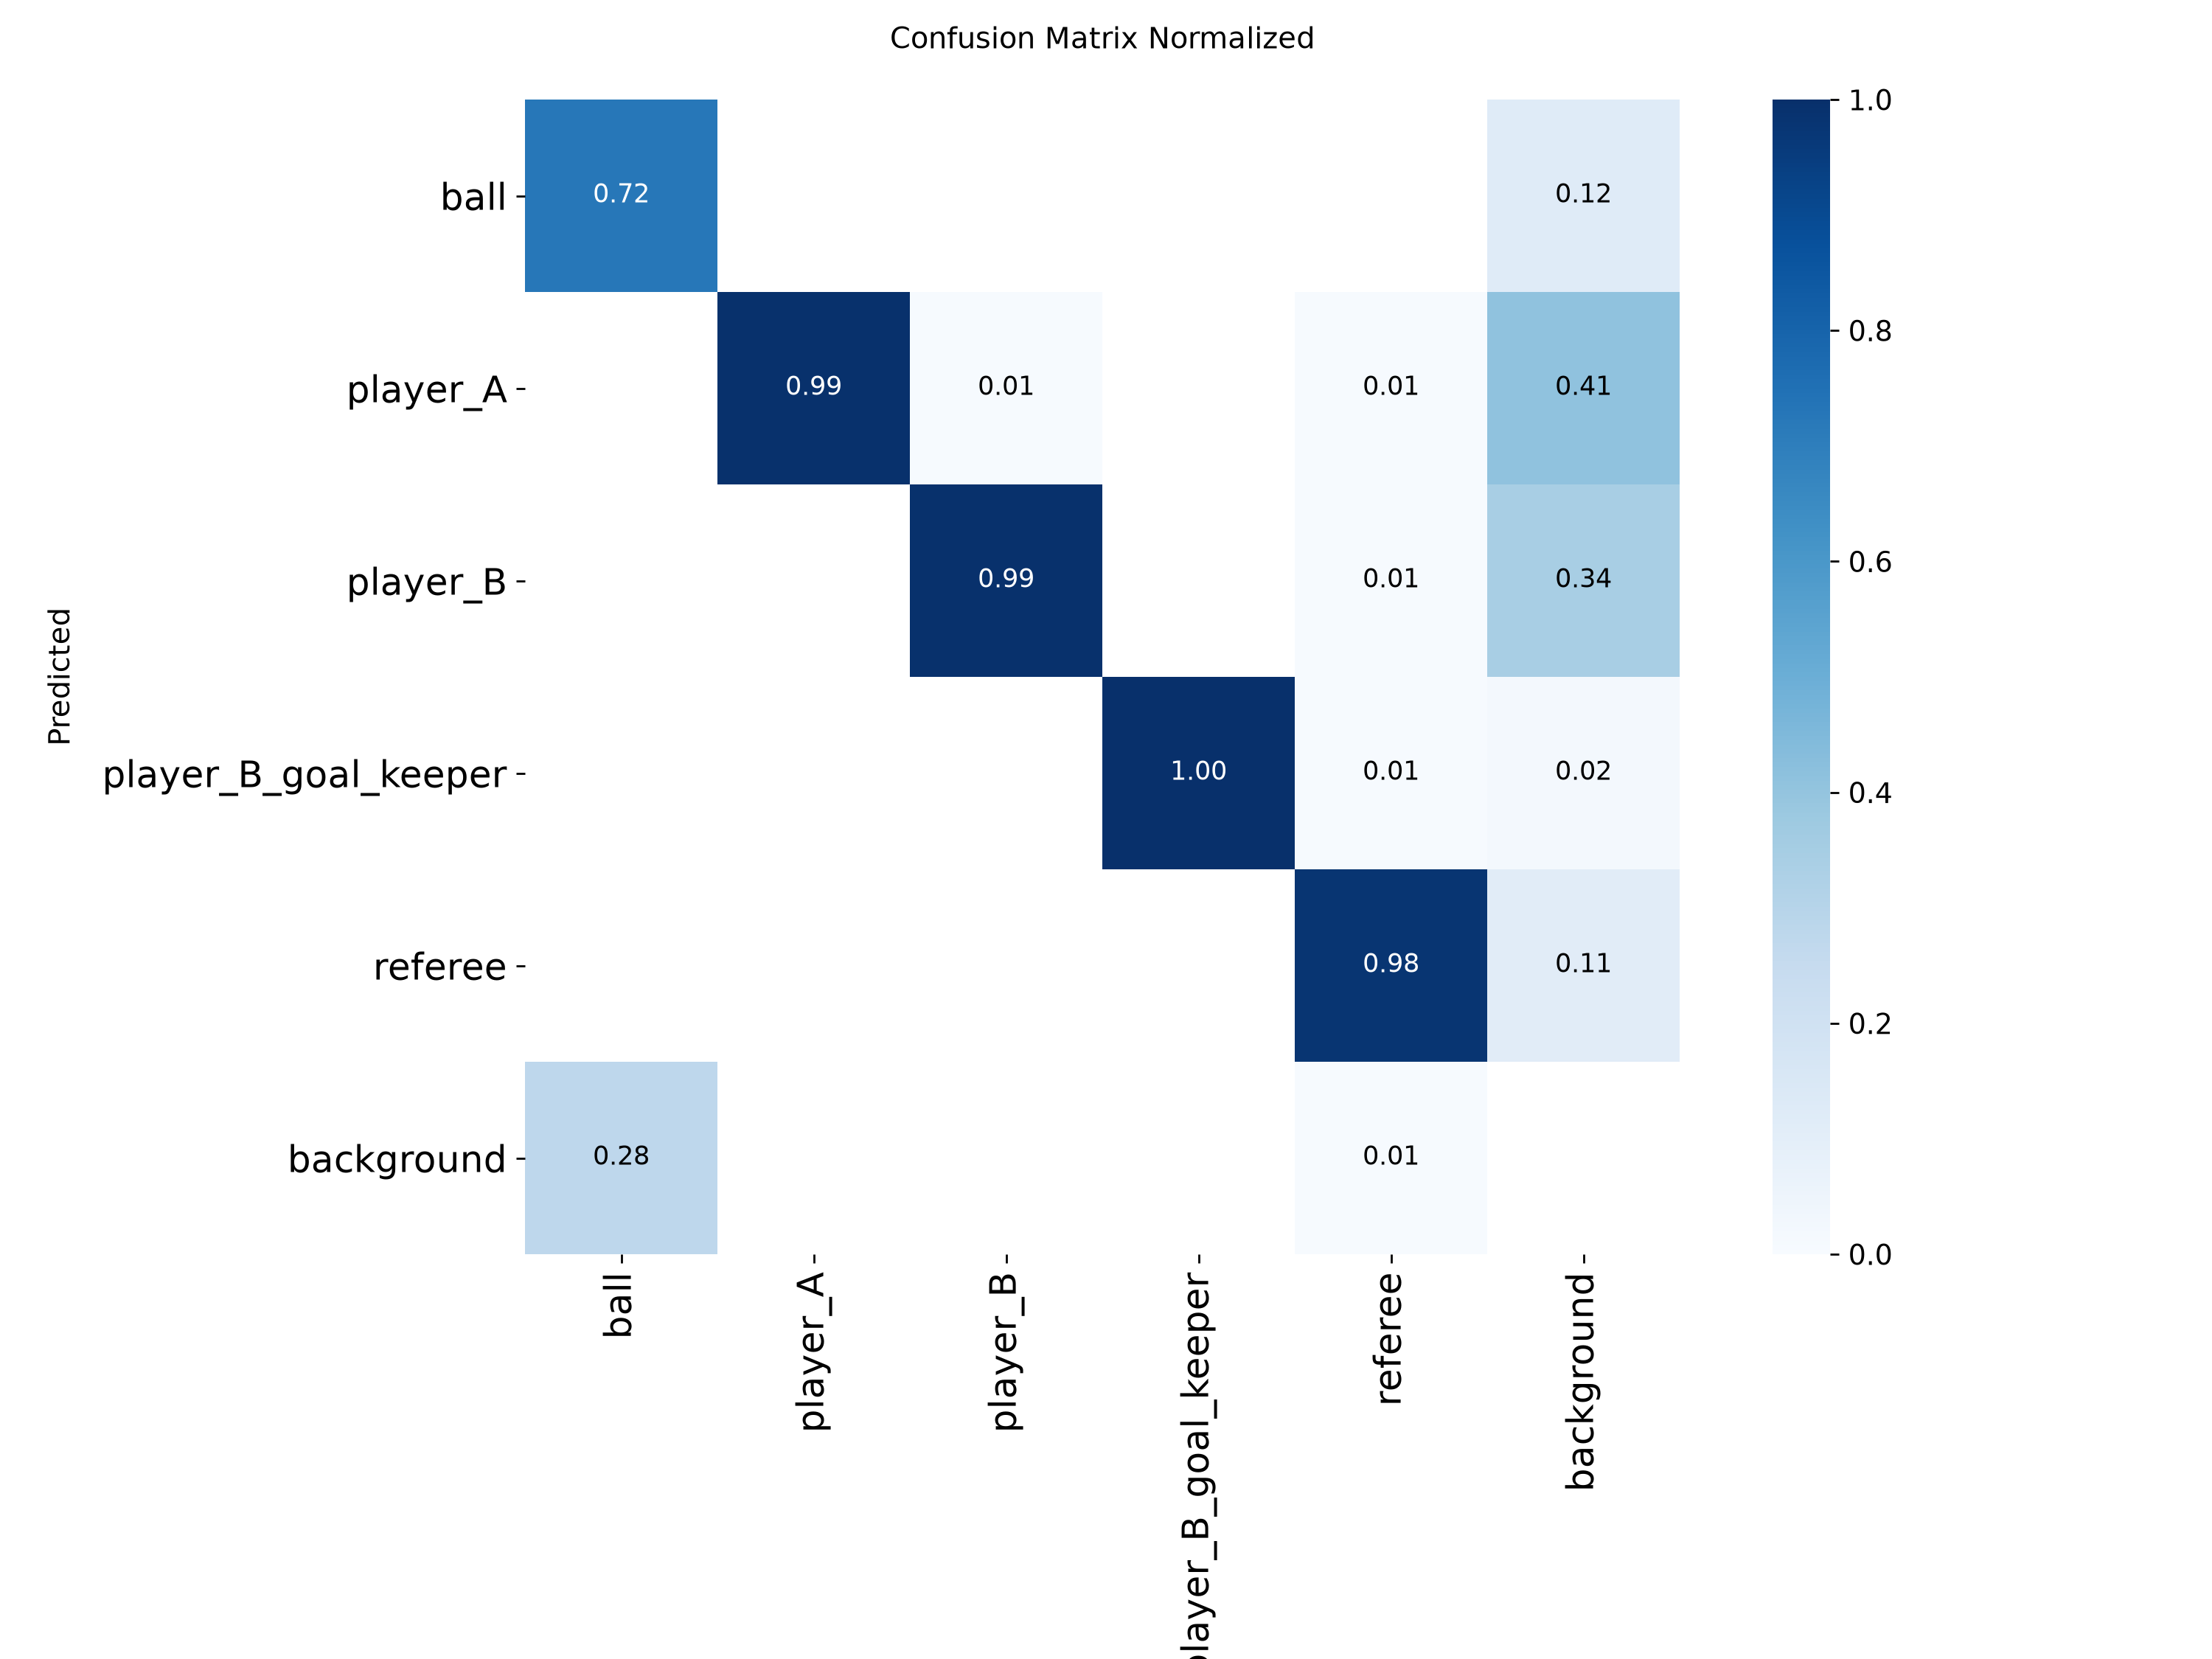

In [22]:
display(Image(filename=str(RES / "figures" / "final_model" / "confusion_matrix_normalized.png"), width=640))

**Wat zien we?** Zelfs op zijn eigen trainingsbeelden vindt het model maar 72 % van de ballen; 28 % wordt gemist (rij `background` in de
bal-kolom). Verwarring tussen de teams komt bijna niet meer voor (0,01). Bij Kobe's smoke test met yolo26s op 640 was die verwarring nog groot
(zie de README van de smoke test). De kolom `background` toont de valse detecties: die zijn vooral "speler PSG" (41 %) en "speler Inter" (34 %),
dus personen waar geen label staat. Dat zijn waarschijnlijk wisselspelers, stewards of mensen langs de lijn, die volgens ons protocol niet
gelabeld zijn. Een kleiner deel van de valse detecties is een bal (12 %) of een scheidsrechter (11 %).

### 4.4 Het model op een beeld dat het nooit zag

Ter illustratie halen we één beeld uit het weinig gelabelde middenstuk van de clip (frame 450, niet in de 136 trainingsbeelden) door het
model. Op de processor duurt dat een paar seconden. We gebruiken imgsz 960, de trainingsresolutie.

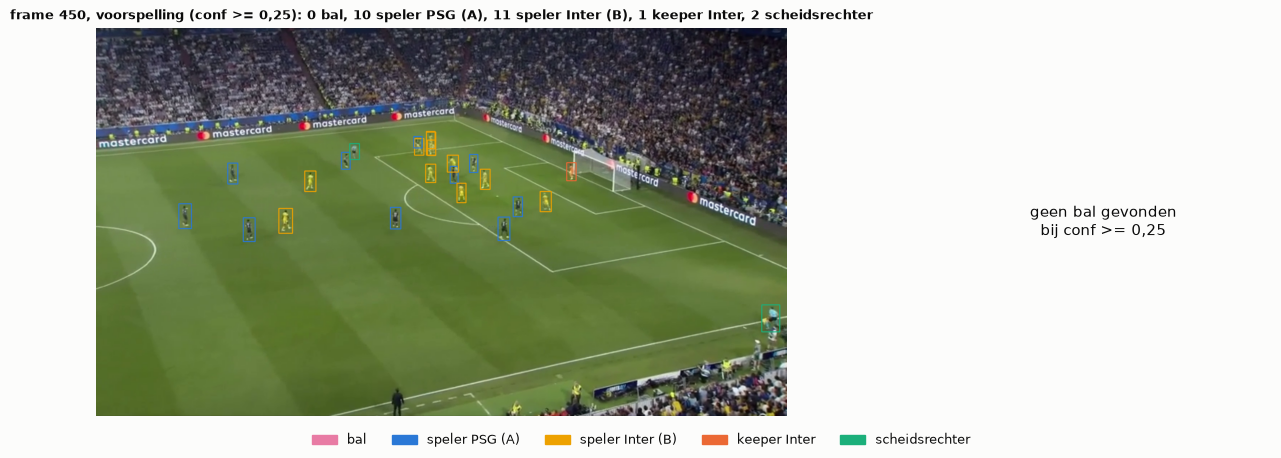

In [23]:
f = 450
assert f not in v4_frames
img = read_frame(f)
res = yolo.predict(img[:, :, ::-1], imgsz=960, conf=0.25, verbose=False)[0]
pred = [(CLASSES[int(c)], *xywh) for c, xywh in zip(res.boxes.cls.tolist(), res.boxes.xywh.tolist())]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [3.2, 1]})
out = draw(img, pred, 2)
axes[0].imshow(out); axes[0].axis("off")
cnt = pd.Series([p[0] for p in pred]).value_counts()
axes[0].set_title(f"frame {f}, voorspelling (conf >= 0,25): " + ", ".join(f"{cnt.get(c, 0)} {CLASS_NL[c]}" for c in CLASSES), fontsize=9.5)
balls = [(p, s) for p, s in zip(pred, res.boxes.conf.tolist()) if p[0] == "ball"]
if balls:
    (_, cx, cy, bw, bh), s = balls[0]
    cx, cy = int(cx), int(cy)
    axes[1].imshow(out[max(cy - 60, 0):cy + 60, max(cx - 60, 0):cx + 60], interpolation="nearest")
    axes[1].set_title(f"bal, confidence {s:.2f}", fontsize=9.5)
else:
    axes[1].text(0.5, 0.5, "geen bal gevonden\nbij conf >= 0,25", ha="center", va="center", fontsize=11)
axes[1].axis("off")
fig.legend(handles=[mpatches.Patch(color=CLASS_COLOR[c], label=CLASS_NL[c]) for c in CLASSES], ncol=5, loc="lower center", fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Wat zien we?** Op een beeld dat het model nooit zag, vindt het de spelers van beide teams, de keeper en de grensrechter. Er zijn wel 11 boxen
"speler Inter", terwijl Inter maar 10 veldspelers heeft. Minstens één box is dus fout: een dubbele box of een speler die het verkeerde team kreeg.
De bal vindt het model op dit beeld niet bij een drempel van 0,25. Dat is precies het zwakke punt uit sectie 2.4. Dit is één beeld en dus geen meting. De systematische evaluatie op handmatig aangeklikte frames staat in notebook 02 en de evaluatienotebooks.

## 5. Hoe de training werkt

### 5.1 Transfer learning in één alinea

Een YOLO-model vanaf nul trainen vraagt honderdduizenden gelabelde beelden. Wij hebben er 136. Daarom laden we de gewichten van een model
dat op COCO (ongeveer 118 000 beelden, 80 klassen) getraind is. De backbone en de neck herkennen dan al randen, texturen, menselijke vormen en
ballen. Ultralytics vervangt alleen de laatste klassenlaag (80 naar 5 uitgangen) en traint daarna het hele netwerk verder op onze data
(fine-tuning). Daardoor zakt het klassenverlies al in de eerste epochs sterk (sectie 3.4) en volstaan een paar honderd voorbeelden per klasse.
Meer uitleg staat in `uitleg/01_yolo_en_transfer_learning.md`.

### 5.2 De echte trainingscode

Dit is het script waarmee het finale model getraind is (het script `train_players.py` van Cisse, ingekort). Het staat hier ter
uitleg; dezelfde instellingen worden in **sectie 6** echt uitgevoerd, met paden binnen deze map. Bij Cisse duurde de training 55 minuten op een GPU.

```python
from ultralytics import YOLO

model = YOLO("yolo26l.pt")          # COCO-pretrained YOLO26 large
model.train(
    data="data/dataset_yolo/data.yaml",   # export v4: 136 images, train = val
    epochs=100,          # maximum number of passes over the data
    patience=25,         # early stopping after 25 epochs without improvement of mAP50-95
    imgsz=960,           # images resized to 960 px on the long side
    batch=2,             # 2 images per step (GPU memory); gradients are accumulated to nbs = 64
    cos_lr=True,         # cosine learning-rate schedule
    mosaic=0.0,          # no mosaic: it would shrink the already tiny ball
    mixup=0.15,          # 15 % of the images blended with another image
    copy_paste=0.1,      # paste objects from other images (only effective with segment labels)
    scale=0.2,           # random zoom of +-20 % instead of the default +-50 %
    cache=True,          # keep decoded images in RAM
    workers=4,
)
```

Brents trainingsaanroep (zijn script `train_smoke.py`) is vergelijkbaar, maar met `yolo26m.pt`, `imgsz=1600`, `patience=20`
en zijn eigen tijdsblok-split in `data_smoke.yaml`. De bal-fine-tune (het script `finetune_ball.py` van de GPU-job) start van ons model:

```python
model = YOLO("models/best.pt")      # = psg_vs_inter_CV.pt
model.train(data="datasets/ball_finetune/data.yaml", imgsz=1280, batch=4, epochs=60, patience=15,
            seed=0, deterministic=True, cos_lr=True, close_mosaic=10, cls_pw=0.5)
```

### 5.3 De belangrijkste hyperparameters en wat ze doen

| parameter | waarde in het finale model | wat het doet |
|---|---|---|
| `imgsz` | 960 | beeldgrootte tijdens training. Hoger betekent dat kleine objecten meer pixels krijgen, maar het kost kwadratisch meer geheugen en rekentijd |
| `epochs` / `patience` | 100 / 25 | maximaal aantal rondes over de data; stop eerder als de mAP50-95 25 epochs niet verbetert |
| `batch` / `nbs` | 2 / 64 | 2 beelden per stap; ultralytics telt de gradiënten van 32 stappen op voor één update (nominale batch 64) |
| `optimizer` / `lr0` | auto → AdamW / 0,001111 | bij korte trainingen kiest ultralytics AdamW met een learning rate die afhangt van het aantal klassen |
| `warmup_epochs` | 3 | de learning rate groeit de eerste 3 epochs geleidelijk, zodat de COCO-gewichten niet meteen door grote stappen verstoord worden |
| `cos_lr` / `lrf` | true / 0,01 | de learning rate daalt volgens een cosinus tot 1 % van lr0 |
| `weight_decay` | 0,0005 | kleine straf op grote gewichten (regularisatie) |
| `mosaic` / `close_mosaic` | 0 / 10 | mosaic plakt 4 beelden samen (meer context, maar kleinere objecten); de laatste 10 epochs staat het sowieso uit |
| `mixup` | 0,15 | 15 % van de beelden wordt half doorzichtig met een ander beeld gemengd (regularisatie) |
| `copy_paste` | 0,1 | plakt objecten uit andere beelden. Werkt alleen met segmentatiemaskers, bij onze boxlabels heeft het geen effect |
| `scale` / `translate` | 0,2 / 0,1 | willekeurig in- en uitzoomen (±20 %) en verschuiven (±10 %) |
| `fliplr` | 0,5 | de helft van de beelden wordt horizontaal gespiegeld. Een voetbalveld is links-rechts symmetrisch, dus dat mag |
| `hsv_h`, `hsv_s`, `hsv_v` | 0,015 / 0,7 / 0,4 | willekeurige wijziging van tint, verzadiging en helderheid. De tint verandert bewust maar weinig, want de shirtkleur bepaalt het team |
| `erasing` | 0,4 | wist willekeurige rechthoeken (alleen voor classificatie; bij detectie niet gebruikt) |
| `box` / `cls` | 7,5 / 0,5 | gewichten van box- en klassenverlies in het totale verlies |

De augmentaties zijn goed te zien in een trainingsbatch die ultralytics bewaarde. Hieronder staat de eerste batch van de finale run: elk beeld
is willekeurig verschoven, geschaald, gespiegeld of van kleur veranderd, en soms gemengd met een tweede beeld (mixup).

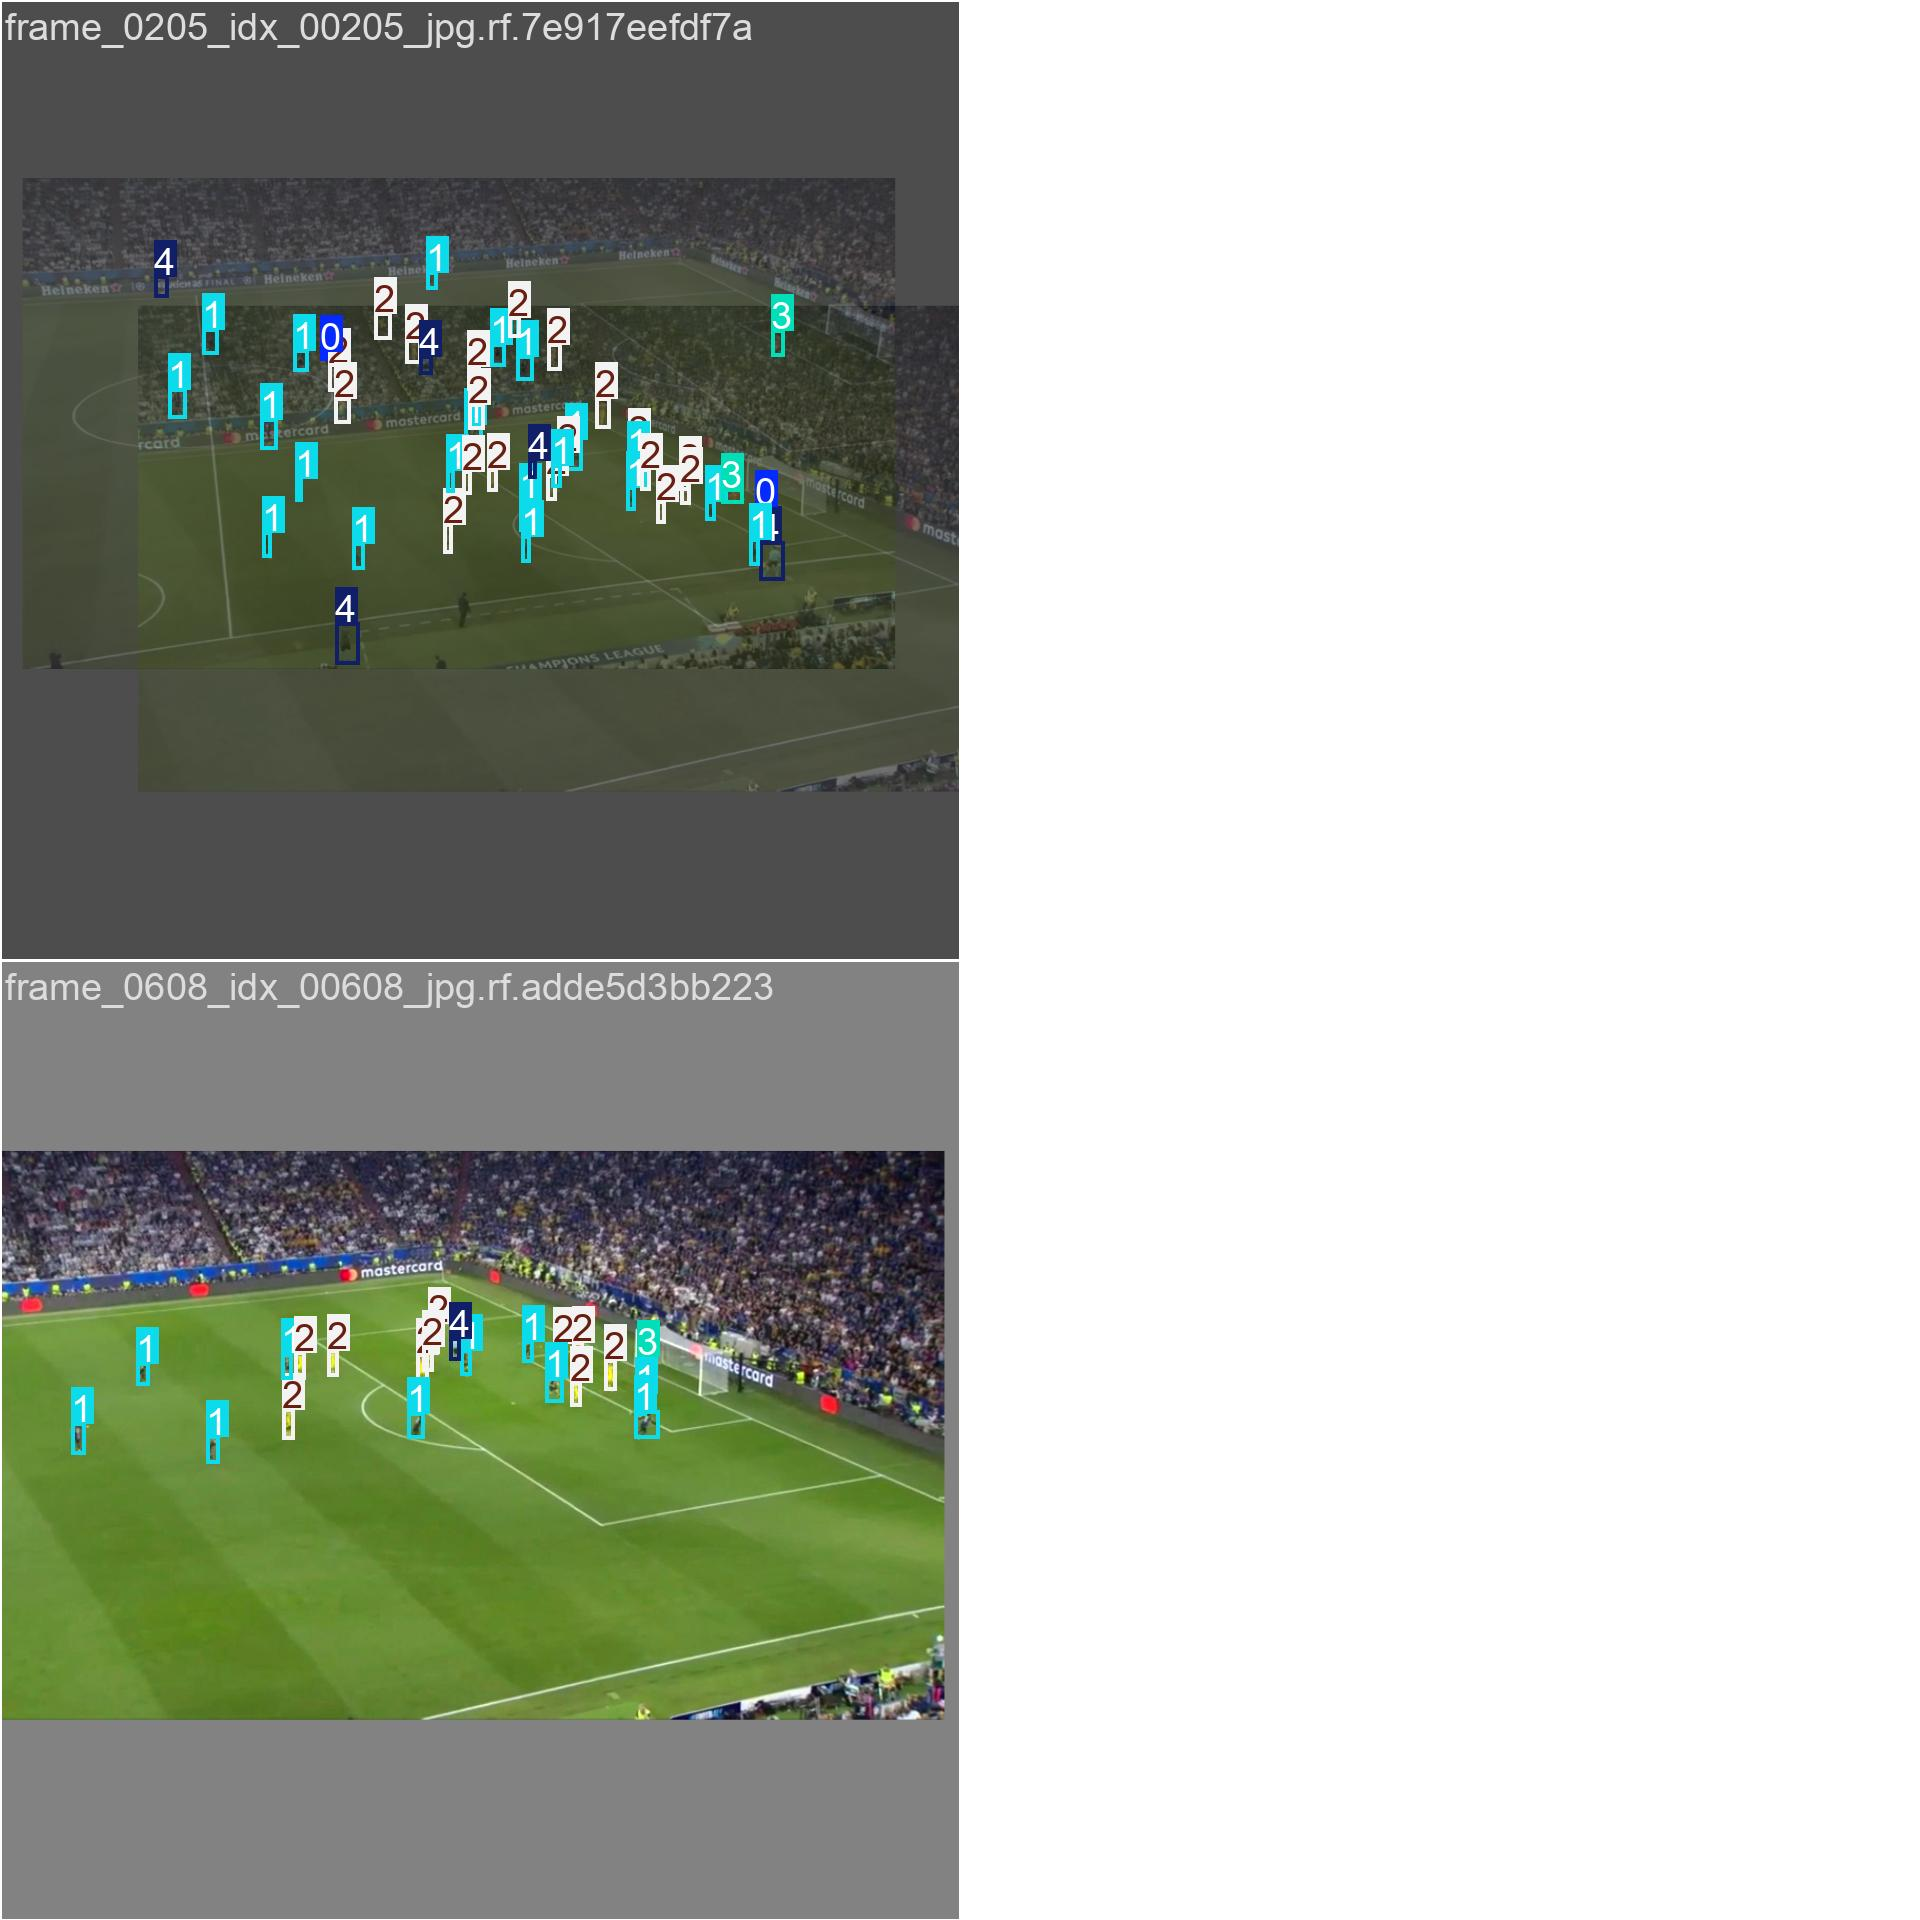

In [24]:
display(Image(filename=str(RES / "figures" / "final_model" / "train_batch0.jpg"), width=900))

**Controle van de learning rate.** De waarde die ultralytics koos, rekenen we na met dezelfde formule. Ook het aantal iteraties, dat de keuze
tussen AdamW en MuSGD (de nieuwe optimizer van YOLO26) bepaalt, volgt uit de dataset:

In [25]:
import math
nc, n_img, nbs = 5, len(v4), ta["nbs"]
lr_fit = round(0.002 * 5 / (4 + nc), 6)
iterations = math.ceil(n_img / max(ta["batch"], nbs)) * ta["epochs"]
print(f"lr0 volgens de formule: {lr_fit} | in het model: {ta['lr0']} | optimizer in het model: {ta['optimizer']}")
print(f"iteraties = ceil({n_img} / max({ta['batch']}, {nbs})) x {ta['epochs']} = {iterations} (< 10 000 -> AdamW, anders MuSGD)")
print(f"gradient accumulation: {max(round(nbs / ta['batch']), 1)} stappen van {ta['batch']} beelden per gewichtsupdate")

lr0 volgens de formule: 0.001111 | in het model: 0.001111 | optimizer in het model: AdamW
iteraties = ceil(136 / max(2, 64)) x 100 = 300 (< 10 000 -> AdamW, anders MuSGD)
gradient accumulation: 32 stappen van 2 beelden per gewichtsupdate


## 6. Het model zelf trainen

Tot hier beschreef dit notebook de training die al gebeurd is. In deze sectie wordt het model **opnieuw getraind**, vanaf de
COCO-gewichten, met alleen bestanden uit deze map:

| wat | waar |
|---|---|
| trainingsdata | `data/datasets/final_train_v4/`: de 136 gelabelde beelden van export v4, exact de set waarop het finale model trainde (teruggehaald uit de git-commit van die training en vergeleken met de bestandslijst uit zijn labelcache) |
| basismodel | `models/basis/yolo26l.pt`: YOLO26l met COCO-gewichten. Ontbreekt het bestand, dan downloadt ultralytics het |
| trainingscode | de twee cellen hieronder: de instellingen en de functie `train()` staan volledig in dit notebook |
| uitvoer | `models/runs/<naam>/`: `weights/best.pt`, `results.csv`, `args.yaml`, het log en de figuren van ultralytics. Na een demonstratierun ruimt het notebook die map weer op |

Er zijn twee standen:

* **`full`**: de instellingen van het finale model (100 epochs, patience 25, beeldgrootte 960, batch 2, cosinusschema, geen mosaic, mixup 0,15,
  scale 0,2, seed 0). Dit vraagt een NVIDIA-GPU; bij Cisse duurde het 55 minuten.
* **`demo`**: dezelfde code, hetzelfde basismodel en dezelfde data, maar 1 epoch op beeldgrootte 320 met 15 % van de beelden. Dat duurt ongeveer
  een minuut op een laptop zonder GPU. Het resultaat is **geen bruikbaar model**; de run toont alleen aan dat de training van begin tot eind werkt.

Met `MODE = "auto"` kiest het notebook `full` als er een CUDA-GPU is en anders `demo`. Zet `MODE = "full"` om de volledige training af te dwingen.
Het bestaande model `models/psg_vs_inter_CV.pt` wordt nooit overschreven.

In [26]:
# Training code. MODE: "auto" = full training on a CUDA GPU, short demo run otherwise; "full" / "demo" force one.
import logging
import shutil
import time

import torch
from ultralytics import YOLO
from ultralytics.utils import LOGGER

MODE = "auto"

TRAIN_DATA = DS / "final_train_v4" / "data.yaml"       # the 136 labelled images the final model was trained on
BASE_WEIGHTS = FU / "models" / "basis" / "yolo26l.pt"  # COCO-pretrained YOLO26l
RUNS_DIR = FU / "models" / "runs"                      # output: models/runs/<name>/

# The settings of the final model (Cisse's run; equal to the train_args stored in psg_vs_inter_CV.pt)
FULL = dict(
    epochs=100,          # maximum number of passes over the data
    patience=25,         # early stopping after 25 epochs without improvement
    imgsz=960,           # images resized to 960 px on the long side
    batch=2,             # 2 images per step (GPU memory); gradients are accumulated to a nominal batch of 64
    cos_lr=True,         # cosine learning-rate schedule
    mosaic=0.0,          # no mosaic: it would shrink the already tiny ball
    mixup=0.15,          # 15 % of the images blended with another image
    copy_paste=0.1,      # only effective with segmentation labels; kept to match the original run
    scale=0.2,           # random zoom of +-20 % instead of the default +-50 %
    cache=True,          # keep decoded images in RAM
    seed=0,
    deterministic=True,
)
# A short run that finishes in about a minute on a laptop CPU: same code, base model and data, but the
# resulting model is useless (1 epoch, small images, 15 % of the data).
DEMO = {**FULL, "epochs": 1, "imgsz": 320, "fraction": 0.15, "cache": False, "plots": False}


def keep_label_cache_out_of_dataset():
    """Stop ultralytics from writing labels.cache into the dataset folder (best effort, version dependent)."""
    try:
        import ultralytics.data.dataset as dataset

        def no_save(prefix, path, cache, version):
            cache["version"] = version

        dataset.save_dataset_cache_file = no_save
    except Exception:   # an internal name changed: training still works, a labels.cache file appears
        pass


def train(mode, name=None, workers=0, **overrides):
    """Train from the COCO weights and return {"mode", "run_dir", "best", "results_csv", "seconds", "device"}.

    mode: "full" (settings of the final model) or "demo" (short CPU run); overrides: any ultralytics train
    argument, e.g. epochs=50. The ultralytics log goes to models/runs/<name>/train_log.txt, not to the notebook.
    """
    settings = {**(FULL if mode == "full" else DEMO), **overrides}
    name = name or ("psg_vs_inter_retrain" if mode == "full" else "demo")
    device = 0 if torch.cuda.is_available() else "cpu"
    run_dir = (RUNS_DIR / name).resolve()
    run_dir.mkdir(parents=True, exist_ok=True)
    keep_label_cache_out_of_dataset()
    # without the local file ultralytics downloads the COCO weights by name (needs internet)
    model = YOLO(str(BASE_WEIGHTS) if BASE_WEIGHTS.is_file() else "yolo26l.pt")
    handler = logging.FileHandler(run_dir / "train_log.txt", mode="w", encoding="utf-8")
    console, LOGGER.handlers = LOGGER.handlers, [handler]
    t0 = time.time()
    try:
        model.train(data=str(TRAIN_DATA.resolve()), project=str(run_dir.parent), name=name, exist_ok=True,
                    device=device, workers=workers, **settings)
    finally:
        LOGGER.handlers = console
        handler.close()
    return {"mode": mode, "run_dir": run_dir, "best": run_dir / "weights" / "best.pt",
            "results_csv": run_dir / "results.csv", "seconds": round(time.time() - t0, 1), "device": str(device)}


mode = MODE if MODE != "auto" else ("full" if torch.cuda.is_available() else "demo")
n_img = len(list((DS / "final_train_v4" / "train" / "images").glob("*.jpg")))
n_lab = len(list((DS / "final_train_v4" / "train" / "labels").glob("*.txt")))
print(f"CUDA-GPU beschikbaar: {torch.cuda.is_available()}  ->  stand: {mode}")
print(f"Trainingsdata: {n_img} beelden, {n_lab} labelbestanden | basismodel aanwezig: {BASE_WEIGHTS.is_file()}")
display(pd.DataFrame({"full (finale model)": pd.Series(FULL), "demo": pd.Series(DEMO)}).fillna("standaard").astype(str))

CUDA-GPU beschikbaar: False  ->  stand: demo
Trainingsdata: 136 beelden, 136 labelbestanden | basismodel aanwezig: True


,full (finale model),demo
batch,2,2
cache,True,False
copy_paste,0.1,0.1
cos_lr,True,True
deterministic,True,True
epochs,100,1
fraction,standaard,0.15
imgsz,960,320
mixup,0.15,0.15
mosaic,0.0,0.0


### 6.1 De training starten

De cel hieronder roept `model.train(...)` van ultralytics aan via de functie `train()` uit de vorige cel. Het uitgebreide log van ultralytics (architectuur, een regel per epoch) gaat naar
`models/runs/<naam>/train_log.txt`; de cel erna toont de samenvatting. `workers=0` laadt de beelden in het hoofdproces, wat in een notebook op Windows
het betrouwbaarst is.

In [27]:
%%capture train_output
# Train. In demo mode this takes about a minute on a laptop CPU; in full mode about an hour on a GPU.
run = train(mode)

In [28]:
# Summary of the run that just finished
trained = pd.read_csv(run["results_csv"])
trained.columns = [col.strip() for col in trained.columns]
size_mb = run["best"].stat().st_size / 1e6
print(f"Stand: {run['mode']} | apparaat: {run['device']} | duur: {run['seconds']:.0f} s | epochs uitgevoerd: {len(trained)}")
print(f"Gewichten geschreven: {run['best'].relative_to(FU.resolve()).as_posix()} ({size_mb:.1f} MB)")
cols = ["epoch", "train/box_loss", "train/cls_loss", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"]
display(trained[[col for col in cols if col in trained.columns]].tail(10).round(4))

# The trained file is a normal ultralytics model with our 5 classes
new_ckpt = torch.load(run["best"], map_location="cpu", weights_only=False)
print("Klassen in het nieuwe model:", list(new_ckpt["model"].names.values()))
print("Basismodel:", Path(str(new_ckpt["train_args"]["model"])).name, "| imgsz:", new_ckpt["train_args"]["imgsz"],
      "| epochs:", new_ckpt["train_args"]["epochs"])

# A few telling lines from the ultralytics log
print()
print("Uit het trainingslog:")
for line in (run["run_dir"] / "train_log.txt").read_text(encoding="utf-8").splitlines():
    if any(key in line for key in ("Transferred", "AdamW(", "Overriding", "epochs completed", " train, ")):
        print("  ", re.sub(r"\x1b\[[0-9;]*m", "", line).strip())

Stand: demo | apparaat: cpu | duur: 36 s | epochs uitgevoerd: 1
Gewichten geschreven: models/runs/demo/weights/best.pt (52.9 MB)


,epoch,train/box_loss,train/cls_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,2.6489,4.9779,0.2217,0.029,0.0075,0.0012


Klassen in het nieuwe model: ['ball', 'player_A', 'player_B', 'player_B_goal_keeper', 'referee']
Basismodel: yolo26l.pt | imgsz: 320 | epochs: 1

Uit het trainingslog:
   Overriding model.yaml nc=80 with nc=5
   Transferred 1080/1092 items from pretrained weights
   optimizer: AdamW(lr=0.001111, momentum=0.9) with parameter groups 178 weight(decay=0.0), 190 weight(decay=0.0005), 190 bias(decay=0.0)
   Using 20 train, 136 val images for fraction=0.15 at imgsz=320
   1 epochs completed in 0.006 hours.


**Wat zien we?** De training loopt van begin tot eind: ultralytics laadt de COCO-gewichten, vervangt de klassenlaag door onze 5 klassen, traint,
valideert en schrijft `best.pt` weg. Het bestand bevat onze klassenamen en de gebruikte trainingsinstellingen.

Staat hierboven `Stand: demo`, lees de metrics dan **niet** als resultaat. Na 1 epoch op kleine beelden en een fractie van de data kan het
model nog niets; een mAP van bijna 0 is dan normaal. De cijfers van het finale model (mAP50 0,895 op de trainingsbeelden na 100 epochs,
sectie 3.4) komen uit de volledige run.

In [29]:
# Full run: compare the new training curve with the original run of the final model (section 3.4).
# Demo run: nothing to compare; remove the run folder (two 53 MB weight files of a useless model).
if run["mode"] == "full":
    orig = results["cisse_4_final_yolo26l_960"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, col, title in ((axes[0], "metrics/mAP50(B)", "mAP50"), (axes[1], "metrics/mAP50-95(B)", "mAP50-95")):
        ax.plot(orig["epoch"], orig[col], color=RUN_COLOR["cisse_4_final_yolo26l_960"], label="oorspronkelijke run (Cisse)")
        ax.plot(trained["epoch"], trained[col], color="#eb6834", label="deze hertraining")
        ax.set_xlabel("epoch"); ax.set_ylabel(title + " (op de trainingsbeelden)"); ax.set_title(title + " per epoch"); ax.legend()
    plt.tight_layout(); plt.show()
    print("Nieuwe gewichten:", run["best"].relative_to(FU.resolve()).as_posix())
else:
    shutil.rmtree(run["run_dir"])
    print("Demonstratierun: de map", run["run_dir"].relative_to(FU.resolve()).as_posix(),
          "is weer verwijderd (geen bruikbaar model).")

Demonstratierun: de map models/runs/demo is weer verwijderd (geen bruikbaar model).


### 6.2 Het hertrainde model gebruiken

Na een volledige run staat het nieuwe model in `models/runs/psg_vs_inter_retrain/weights/best.pt`. Om het in de app en de andere notebooks te
gebruiken:

1. Kopieer het naar `models/` onder een eigen naam (bv. `psg_vs_inter_CV_retrained.pt`) en kies het in de Streamlit-app, of geef het mee met `--weights` aan `streamlit/run_all.py`.
2. De opgeslagen YOLO-detecties in `streamlit/cache/` horen bij het oorspronkelijke bestand (de cachesleutel bevat een hash van de inhoud). Voor een
   nieuw model draait de detectie dus opnieuw over de 660 beelden.

Twee kanttekeningen. Een hertraining geeft niet bit voor bit hetzelfde model: `seed=0` en `deterministic=True` leggen de willekeur vast, maar
resultaten verschillen licht tussen GPU's en versies van PyTorch. En deze training herhaalt bewust de oorspronkelijke opzet, dus ook de zwakte
ervan: `val: train/images`, validatie op de trainingsbeelden. Voor een eerlijke validatie tijdens het trainen is `data/datasets/notebook_split/`
bruikbaar (split per tijdsblok, maar gebouwd op de oudere export van 100 beelden).

De evaluatie en afstelling van het getrainde model (beeldgrootte, drempels, NMS, de bal-fine-tune) volgen in **notebook 02**.

## 7. Conclusies

* **Het finale model is gereconstrueerd en bewezen.** `psg_vs_inter_CV.pt` is Cisse's vierde run: YOLO26l vanaf COCO, imgsz 960, 100 epochs,
  batch 2, AdamW (lr0 0,001111, cosinusschema), geen mosaic, mixup 0,15 en scale 0,2, op de 136 beelden van export v4. Instellingen, resultaten per
  epoch en de lijst trainingsbeelden komen alle drie overeen.
* **Twee knoppen maakten het grootste verschil: modelgrootte en resolutie.** Van yolo26n op 640 (mAP50-95 0,43) naar yolo26l op 960 (0,55),
  telkens gemeten op de trainingsbeelden. Ook de runs met eerlijke validatie gingen erop vooruit naarmate model, resolutie en dataset groeiden
  (mAP50 0,47 bij de smoke test, 0,67 tot 0,78 voor de m- en l-modellen op 1600 en 1920 px).
* **De bal blijft het knelpunt.** Hij is in het origineel ongeveer 14 px en na verkleinen naar 960 nog ongeveer 7 px, kleiner dan één cel van het fijnste
  raster. Hij komt maximaal één keer per beeld voor (105 boxen tegen meer dan 2 700 spelers) en lijkt op lijnen en de penaltystip. Zelfs op zijn eigen
  testbeelden vindt het model maar 1 van de 5 ballen. Daarom werkt de pijplijn met een lagere baldrempel, een hogere inferentieresolutie en een
  Kalman-tracker (notebook 02 en verder).
* **Een fine-tune moet zachter dan een training vanaf COCO.** De bal-fine-tune op 1280 px verslechterde vanaf epoch 2. De oorzaak is een te hoge
  learning rate en een andere augmentatie dan in de oorspronkelijke run. Hij is niet in gebruik genomen.

## 8. Beperkingen

* **Geen eerlijke validatie voor het finale model.** Omdat `val: train/images` in de `data.yaml` staat, is mAP50 0,895 / mAP50-95 0,546 gemeten op de
  trainingsbeelden. Ook overfitting is uit die curves niet af te lezen. De eerlijkste aanwijzing zijn Brents run (mAP50 0,78 op 50 ongeziene frames) en
  Kobe's run (0,67 op 23 frames), maar dat zijn andere modellen.
* **Overlap tussen train- en testframes.** De testsplit van notebook_split (frames 600-658), de validatie van de bal-fine-tune (200-245) en 7 van de 22
  GT-frames zitten allemaal in de 136 trainingsbeelden. Elke test van dit model op die frames is te optimistisch. Een eerlijke test vraagt nieuw gelabelde
  frames uit het middenstuk (63-199 en 246-524). Het script `export_unseen_frames.py` (in de projectrepository onder `kobe/match_analyse/gpu/`) zet die klaar.
* **Kleine dataset uit één wedstrijd en één camerastandpunt.** 136 beelden uit één clip van 22 seconden, in drie dichte blokken van
  sterk gelijkende buurbeelden. Het model kent alleen deze shirts, dit licht en deze camerahoek. Op een andere wedstrijd zou het de teams niet herkennen.
* **Zeer kleine validatie- en testsets.** 4 tot 50 beelden en soms maar 5 ballen. Eén object meer of minder verschuift de metrics met procenten tot
  tientallen procenten.
* **Reconstructie met onzekerheden.** Van sommige runs is het precieze aantal beelden afgeleid uit de toestand van de repository bij de commit
  (kolom "zekerheid"). De eerste run van Cisse (1 epoch) en de hardware van Cisse zijn niet terug te vinden. Van Brents runs bestaan alleen de getallen
  in de checkpoints, niet zijn figuren.